<a href="https://colab.research.google.com/github/virajrank48-max/Flood-Risk-Priority-Index/blob/main/indian_flood_risk_priority_index.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Indian Catchment Flood Risk Priority Index

This notebook develops a reproducible catchment-level flood risk priority index using INDOFLOODS flood events, rainfall variables, catchment characteristics and gauge metadata.

**Unit of analysis:** one catchment identified by `GaugeID`.

**Main outputs:** hazard score, exposure/vulnerability score, combined risk-priority score, hazard-exposure quadrants, catchment typology, ranking tables, sensitivity analysis, a Monte Carlo simulation of future flood hazard that tests how stable the priority list is, and maps of India.

## 1. Colab setup and file paths

**Data:** INDOFLOODS (Kuntla & Saharia, 2025, https://doi.org/10.5281/zenodo.14584654). Download the files listed in the README into `data/` before running. See `README.md` for results, method and limitations.

In [ ]:
!pip -q install geopandas folium mapclassify

import os
import re
import glob
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gpd

from scipy.stats import spearmanr
from scipy.interpolate import make_interp_spline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display

In [ ]:
DATA_DIR = os.environ.get('FLOOD_DATA_DIR', 'data')
OUTPUT_DIR = 'outputs'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)
print('Data directory:', DATA_DIR)

Data directory: /content/data


### Expected filenames

- `floodevents_indofloods.csv`
- `precipitation_variables_indofloods.csv`
- `catchment_characteristics_indofloods.csv`
- `metadata_indofloods.csv`
- `catchments_shapefiles_indofloods.zip` (maps)
- Optional: `DFSI.csv`

Download these from the INDOFLOODS `Zenodo` record. DFSI.csv is distributed with the India Flood Inventory-Impacts record (Saharia et al., 2025)

In [ ]:
EVENTS_FILE = os.path.join(DATA_DIR, 'floodevents_indofloods.csv')
RAINFALL_FILE = os.path.join(DATA_DIR, 'precipitation_variables_indofloods.csv')
CATCHMENTS_FILE = os.path.join(DATA_DIR, 'catchment_characteristics_indofloods.csv')
METADATA_FILE = os.path.join(DATA_DIR, 'metadata_indofloods.csv')
DFSI_FILE = os.path.join(DATA_DIR, 'DFSI.csv')

required_files = [EVENTS_FILE, RAINFALL_FILE, CATCHMENTS_FILE, METADATA_FILE]
missing = [p for p in required_files if not os.path.exists(p)]
if missing:
    raise FileNotFoundError('Missing required files: ' + ', '.join(missing) + '. Download them from the INDOFLOODS Zenodo record into the data/ folder (see README).')
events = pd.read_csv(EVENTS_FILE)
rainfall = pd.read_csv(RAINFALL_FILE)
catchments = pd.read_csv(CATCHMENTS_FILE)
metadata = pd.read_csv(METADATA_FILE)

print('Events:', events.shape)
print('Rainfall:', rainfall.shape)
print('Catchments:', catchments.shape)
print('Metadata:', metadata.shape)

Events: (4548, 13)
Rainfall: (4548, 11)
Catchments: (155, 108)
Metadata: (214, 18)


Data frames:

- `events`: information about each flood event
- `rainfall`: rainfall totals for up to 10 days around each event
- `catchments`: physical and socio-economic characteristics of each catchment, identified by `GaugeID` such as INDOFLOODS-gauge-1010
- `metadata`: details of each gauge, including its warning and danger levels

In [ ]:
events.head()

,EventID,Start Date,End Date,Peak Flood Level (m),Peak FL Date,Num Peak FL,Peak Discharge Q (cumec),Peak Discharge Date,Flood Volume (cumec),Event Duration (days),Time to Peak (days),Recession Time (day),Flood Type
0,INDOFLOODS-gauge-1010-1,2010-07-21,2010-07-21,47.950,2010-07-21,1,NaN,NaN,NaN,1,1,1,Flood
1,INDOFLOODS-gauge-1010-2,2016-07-23,2016-07-23,48.050,2016-07-23,1,NaN,NaN,NaN,1,1,1,Flood
2,INDOFLOODS-gauge-1010-3,2016-07-26,2016-07-26,48.000,2016-07-26,1,NaN,NaN,NaN,1,1,1,Flood
3,INDOFLOODS-gauge-1010-4,2017-08-11,2017-08-13,48.950,2017-08-12,1,NaN,NaN,NaN,3,2,2,Severe Flood
4,INDOFLOODS-gauge-1012-1,2010-07-21,2010-07-21,48.100,2010-07-21,1,NaN,NaN,NaN,1,1,1,Flood


In [ ]:
rainfall.head()

,EventID,T1d,T2d,T3d,T4d,T5d,T6d,T7d,T8d,T9d,T10d
0,INDOFLOODS-gauge-1010-1,32.833,65.229,99.413,124.273,133.345,138.143,140.459,155.228,177.372,203.687
1,INDOFLOODS-gauge-1010-2,27.011,60.148,86.528,111.753,136.084,158.516,197.476,216.302,243.308,247.080
2,INDOFLOODS-gauge-1010-3,50.413,82.467,124.859,151.871,185.007,211.388,236.613,260.943,283.376,322.336
3,INDOFLOODS-gauge-1010-4,46.282,86.766,104.849,115.481,125.935,130.959,134.251,148.829,167.936,182.415
4,INDOFLOODS-gauge-1012-1,86.018,137.676,176.841,203.447,215.046,225.185,239.478,284.882,411.164,522.829


In [ ]:
catchments.head()

,GaugeID,Stream Order,Maximal Flow Length,Downvalley Length,Drainage Area,Catchment Relief,Catchment Length,Catchment Perimeter,Sinuosity Index,Form Factor,Relief Ratio,Elongation Ratio,Circularity Ratio,Lemniscates Value,Drainage Texture,Drainage Density,Compactness Coefficient,Wandering Ratio,Fitness Ratio,Basin Magnitude,Channel Frequency,Drainage Intensity,Infiltration Number,Ruggedness Number,No. of Firstorder Streams,No. of Secondorder Streams,No. of Thirdorder Streams,No. of Fourthorder Streams,No. of Fifthorder Streams,No. of Sixthorder Streams,No. of Seventhorder Streams,No. of Eigthorder Streams,Firstorder Streams Length,Secondorder Streams Length,Thirdorder Streams Length,Fourthorder Streams Length,Fifthorder Streams Length,Sixthorder Streams Length,Seventhorder Streams Length,Eighthorder Streams Length,Firstorder Streams Mean Length,Secondorder Streams Mean Length,Thirdorder Streams Mean Length,Fourthorder Streams Mean Length,Fifthorder Streams Mean Length,Sixthorder Streams Mean Length,Seventhorder Streams Mean Length,Eighthorder Streams Mean Length,FirstSecond Stream Length Ratio,SecondThird Stream Length Ratio,ThirdForth Stream Length Ratio,FourthFifth Stream Length Ratio,FifthSixth Stream Length Ratio,SixthSeventh Stream Length Ratio,SeventhEighth Stream Length Ratio,FirstSecond Bifurcation Ratio,SecondThird Bifurcation Ratio,ThirdForth Bifurcation Ratio,FourthFifth Bifurcation Ratio,FifthSixth Bifurcation Ratio,Sixthseventh Bifurcation Ratio,SeventhEighth Bifurcation Ratio,Annual Mean Temperature,Mean Diurnal Range,Isothermality,Temperature Seasonality,Max Temperature of Warmest Month,Min Temperature of Coldest Month,Temperature Annual Range,Mean Temperature of Wettest Quarter,Mean Temperature of Driest Quarter,Mean Temperature of Warmest Quarter,Mean Temperature of Coldest Quarter,Annual Precipitation,Precipitation of Wettest Month,Precipitation of Driest Month,Precipitation Seasonality,Precipitation of Wettest Quarter,Precipitation of Driest Quarter,Precipitation of Warmest Quarter,Precipitation of Coldest Quarter,KoppenGeiger Climate Type,2015_GDP_PPP,2010_GDP_PPP,2005_GDP_PPP,2000_GDP_PPP,1995_GDP_PPP,1990_GDP_PPP,2010_GDP_PC_PPP,2015_GDP_PC_PPP,2005_GDP_PC_PPP,2000_GDP_PC_PPP,1995_GDP_PC_PPP,1990_GDP_PC_PPP,Night Light,Road Density,Urban percentage,2010_HDI,2015_HDI,2005_HDI,2000_HDI,1995_HDI,1990_HDI,Population Count,Population Density,Land cover,Soil type,lithology type
0,INDOFLOODS-gauge-1013,4,"141,541.172","113,605.773","3,542.106",4416,"116,870.219","315,248.281",1.246,0.259,0.038,0.000,0.448,3.856,0.000,0.000,1.505,1.211,0.449,36,0.000,0.000,0.000,0.849,36,10.000,4.000,1.000,NaN,NaN,NaN,NaN,"341,966.156","145,076.844","156,550.656","37,154.520",NaN,NaN,NaN,NaN,"9,499.060","14,507.685","39,137.664","37,154.520",NaN,NaN,NaN,NaN,0.424,1.079,0.237,NaN,NaN,NaN,NaN,3.600,2.500,4.000,NaN,NaN,NaN,NaN,22.249,8.868,45.535,385.878,29.520,10.060,19.459,26.001,17.628,26.001,16.725,"3,464.794",841.055,6.799,105.068,"2,202.791",38.208,"2,198.848",51.489,Temperate,"200,538,660.100","146,530,759.400","103,152,813.200","83,021,509.120","56,862,700.900","46,763,628.170","4,724.294","5,922.348","3,428.862","2,855.569","2,196.038","1,912.649",1.773,197.111,36.632,0.606,0.649,0.568,0.532,0.501,0.472,"1,656,813.000",465.075,No dominant class,Cambisols,Unconsolidated sediments
1,INDOFLOODS-gauge-1018,5,"277,715.594","183,743.906","9,908.034",7735,"201,079.812","607,907.062",1.511,0.245,0.038,0.000,0.337,4.081,0.000,0.000,1.735,1.381,0.457,136,0.000,0.000,0.000,1.218,136,29.000,9.000,2.000,1.000,NaN,NaN,NaN,"794,714.750","330,012.469","179,696.250","147,985.109","108,017.250",NaN,NaN,NaN,"5,843.491","11,379.740","19,966.250","73,992.555","108,017.250",NaN,NaN,NaN,0.415,0.545,0.824,0.730,NaN,NaN,NaN,4.690,3.222,4.500,2.000,NaN,NaN,NaN,10.737,9.845,44.157,475.237,19.905,-2.498,22.403,15.903,5.560,15.961,4.412,"1,899.770",463.423,5.414,99.253,"1,191.166",32.200,"1,190.207",44.422,Temperate,"104,349,547.400","75,502,738.160","

In [ ]:
metadata.head()

,GaugeID,Warning Level,Danger Level,Station,Latitude,Longitude,River Name/ Tributory/ SubTributory,Basin,State,Start_date,End_date,Level_Entries,Streamflow_Entries,Privacy,Source Catchment Area,Catchment Area,Area variation (%),Reliability
0,INDOFLOODS-gauge-394,259.200,262.000,Biligundulu,12.180,77.730,Cauvery,Cauvery,Karnataka,1971-08-30,2020-05-27,17715,17273,Open,"36,682.000","36,889.801",0.566,Safe
1,INDOFLOODS-gauge-118,66.750,67.750,Jainagar,26.583,86.148,Ganga/Kosi/ Kamla-Balan,Ganga - Brahmaputra - Meghna/Barak,Bihar,1970-07-01,2010-12-31,14134,13725,Restricted,"2,131.000","2,118.569",0.583,Safe
2,INDOFLOODS-gauge-119,49.000,50.000,Jhanjharpur,26.233,86.259,Ganga/Kosi/ Kamla-Balan,Ganga - Brahmaputra - Meghna/Barak,Bihar,1970-01-01,2010-12-31,14939,14616,Restricted,"2,945.000","3,504.424",18.996,Safe
3,INDOFLOODS-gauge-121,70.000,71.000,DHENG BRIDGE,26.723,85.323,Ganga/Kosi/ Bagmati,Ganga - Brahmaputra - Meghna/Barak,Bihar,1970-07-01,2010-12-31,14762,14750,Restricted,"3,790.000","3,580.847",5.519,Safe
4,INDOFLOODS-gauge-560,218.000,220.980,Burhanpur,21.299,76.235,Tapi,Tapi,Madhya Pradesh,1972-09-14,2019-08-20,16611,16249,Open,"8,487.000","8,926.981",5.184,Safe


`EventID` and `GaugeID` link the tables: an event ID is the gauge ID followed by an event number.

## 2. Cleaning and quality checks

In [ ]:
def clean_name(name):
    name = str(name).strip()
    name = re.sub(r'[^0-9A-Za-z]+', '_', name)
    return name.strip('_').lower()

events.columns = [clean_name(c) for c in events.columns]
rainfall.columns = [clean_name(c) for c in rainfall.columns]
catchments.columns = [clean_name(c) for c in catchments.columns]
metadata.columns = [clean_name(c) for c in metadata.columns]

events['start_date'] = pd.to_datetime(events['start_date'], errors='coerce')
events['end_date'] = pd.to_datetime(events['end_date'], errors='coerce')
events['peak_fl_date'] = pd.to_datetime(events['peak_fl_date'], errors='coerce')
metadata['start_date'] = pd.to_datetime(metadata['start_date'], errors='coerce')
metadata['end_date'] = pd.to_datetime(metadata['end_date'], errors='coerce')

def extract_gauge_id(event_id):
    return str(event_id).rsplit('-', 1)[0]

events['gauge_id'] = events['eventid'].map(extract_gauge_id)
rainfall['gauge_id'] = rainfall['eventid'].map(extract_gauge_id)

# The catchment table stores the gauge identifier as 'gaugeid'
if 'gaugeid' in catchments.columns:
    catchments['gauge_id'] = catchments['gaugeid']

# Numeric-looking text columns are converted; identifier and label columns are left unchanged
for frame in [events, rainfall, catchments, metadata]:
    for col in frame.columns:
        if frame[col].dtype == 'object' and col not in {'eventid', 'gaugeid', 'gauge_id', 'flood_type', 'station'}:
            converted = pd.to_numeric(frame[col], errors='coerce')
            if converted.notna().mean() > 0.8:
                frame[col] = converted

events = events.drop_duplicates('eventid').copy()
rainfall = rainfall.drop_duplicates('eventid').copy()
events.loc[events['event_duration_days'] < 0, 'event_duration_days'] = np.nan

print(events['event_duration_days'].describe(percentiles=[.5, .9, .99, .999]))
# Durations above 60 days are treated as recording errors
events.loc[events['event_duration_days'] > 60, 'event_duration_days'] = np.nan
print('Unique event IDs:', events['eventid'].nunique())
print('Unique event gauges:', events['gauge_id'].nunique())
print('Catchment gauges:', catchments['gauge_id'].nunique())
print('\nMissingness in core event columns:')
display(events[['eventid', 'start_date', 'end_date', 'peak_flood_level_m',
                'peak_fl_date', 'num_peak_fl', 'peak_discharge_q_cumec',
                'peak_discharge_date', 'flood_volume_cumec', 'event_duration_days',
                'time_to_peak_days', 'recession_time_day', 'flood_type', 'gauge_id']].isna().mean().mul(100).round(2).to_frame('missing_percent'))

count    4,548.000
mean        10.358
std        180.963
min          1.000
50%          2.000
90%          8.000
99%         67.890
99.9%    1,207.260
max     11,147.000
Name: event_duration_days, dtype: float64
Unique event IDs: 4548
Unique event gauges: 155
Catchment gauges: 155

Missingness in core event columns:


,missing_percent
eventid,0.000
start_date,0.000
end_date,0.000
peak_flood_level_m,0.000
peak_fl_date,0.000
num_peak_fl,0.000
peak_discharge_q_cumec,12.200
peak_discharge_date,12.200
flood_volume_cumec,12.690
event_duration_days,1.030


In [ ]:
print('Missingness in core rainfall columns:')
display(rainfall[['eventid', 't1d', 't2d', 't3d', 't4d', 't5d', 't6d', 't7d', 't8d',
                  't9d', 't10d']].isna().mean().mul(100).round(2).to_frame('missing_percent'))

Missingness in core rainfall columns:


,missing_percent
eventid,0.000
t1d,0.000
t2d,0.000
t3d,0.000
t4d,0.000
t5d,0.000
t6d,0.000
t7d,0.000
t8d,0.000
t9d,0.000


In [ ]:
print('Missingness in catchments:')
display(catchments.isna().mean().mul(100).round(2).to_frame('missing_percent'))

Missingness in catchments:


,missing_percent
gaugeid,0.000
stream_order,0.000
maximal_flow_length,0.000
downvalley_length,0.000
drainage_area,0.000
...,...
population_density,0.000
land_cover,0.000
soil_type,0.000
lithology_type,0.000


In [ ]:
print('Missingness in metadata:')
display(metadata.isna().mean().mul(100).round(2).to_frame('missing_percent'))

Missingness in metadata:


,missing_percent
gaugeid,0.000
warning_level,0.000
danger_level,0.930
station,0.000
latitude,0.000
longitude,0.000
river_name_tributory_subtributory,0.000
basin,0.930
state,0.000
start_date,0.000


In [ ]:
event_gauges = set(events['gauge_id'])
rain_gauges = set(rainfall['gauge_id'])
catchment_gauges = set(catchments['gauge_id'])

print('Gauges present in all three analytical tables:', len(event_gauges & rain_gauges & catchment_gauges))
print('Event date range:', events['start_date'].min().date(), 'to', events['start_date'].max().date())
print('Flood types:')
display(events['flood_type'].value_counts(dropna=False).to_frame('events'))

Gauges present in all three analytical tables: 155
Event date range: 1965-07-21 to 2020-09-24
Flood types:


,events
flood_type,
Flood,2919
Severe Flood,1629


In [ ]:
# Zero rainfall totals over 3 and 5 days are treated as missing
for c in ['t3d', 't5d']:
    rainfall.loc[rainfall[c] == 0, c] = np.nan

In [ ]:
station_names = metadata.set_index('gaugeid')['station']

def station_label(gauge_id):
    name = station_names.get(gauge_id, np.nan)
    number = gauge_id.split('-')[-1]
    return f'{name} ({number})' if pd.notna(name) else gauge_id

risk_data['station_label'] = risk_data['gauge_id'].map(station_label)
ranked['station_label'] = ranked['gauge_id'].map(station_label)

## 3. Exploratory data analysis

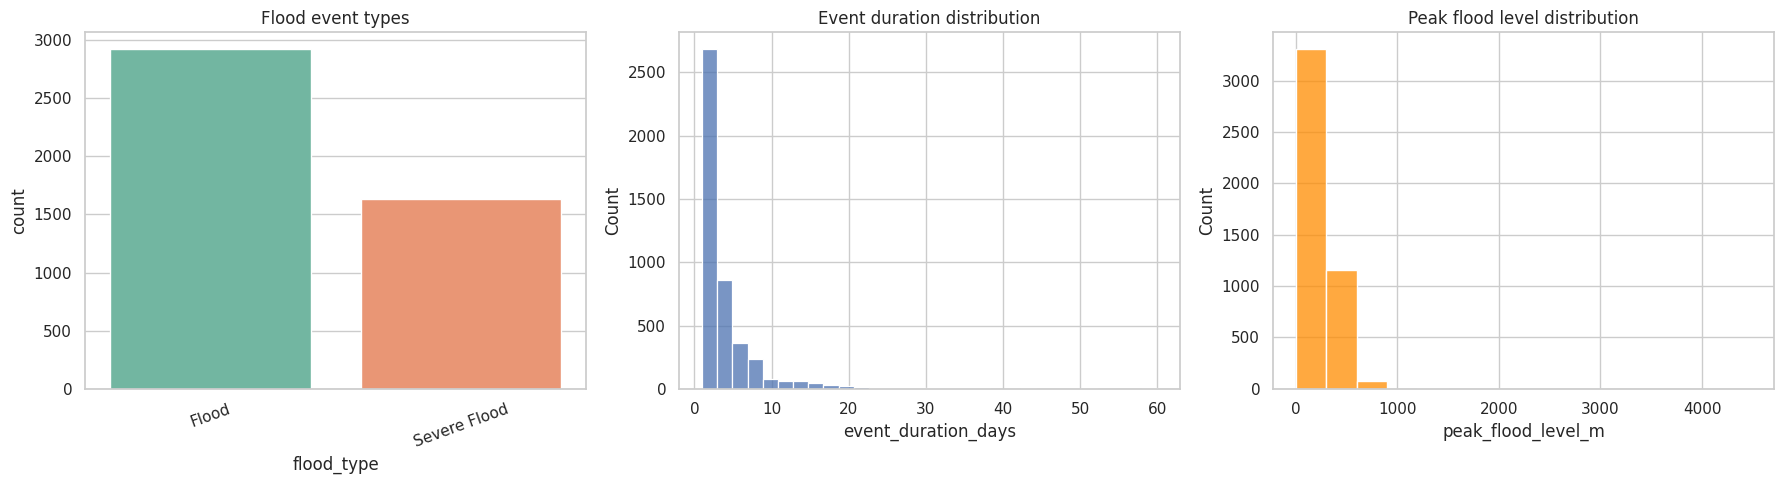

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=events, x='flood_type', ax=axes[0], palette='Set2')
sns.histplot(events.loc[events['event_duration_days']<=60,'event_duration_days'].dropna(), bins=30, ax=axes[1])
axes[0].set_title('Flood event types')
axes[0].tick_params(axis='x', rotation=20)

axes[1].set_title('Event duration distribution')
sns.histplot(events['peak_flood_level_m'].dropna(), bins=15, ax=axes[2], color='darkorange')
axes[2].set_title('Peak flood level distribution')
plt.tight_layout()
plt.show()

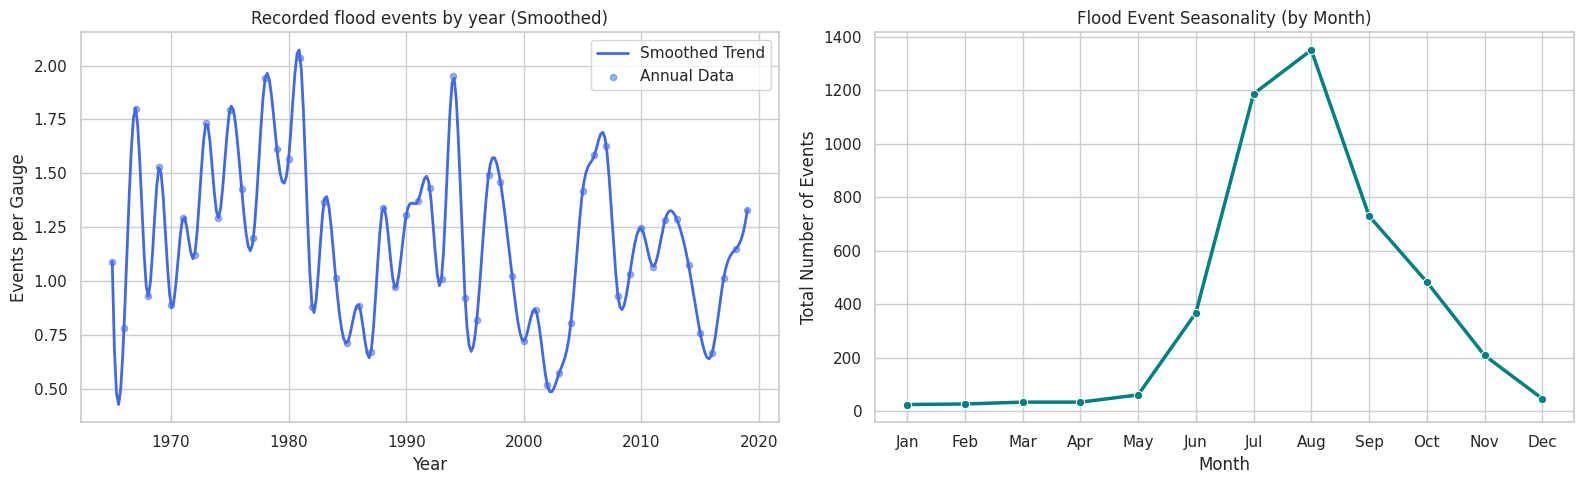

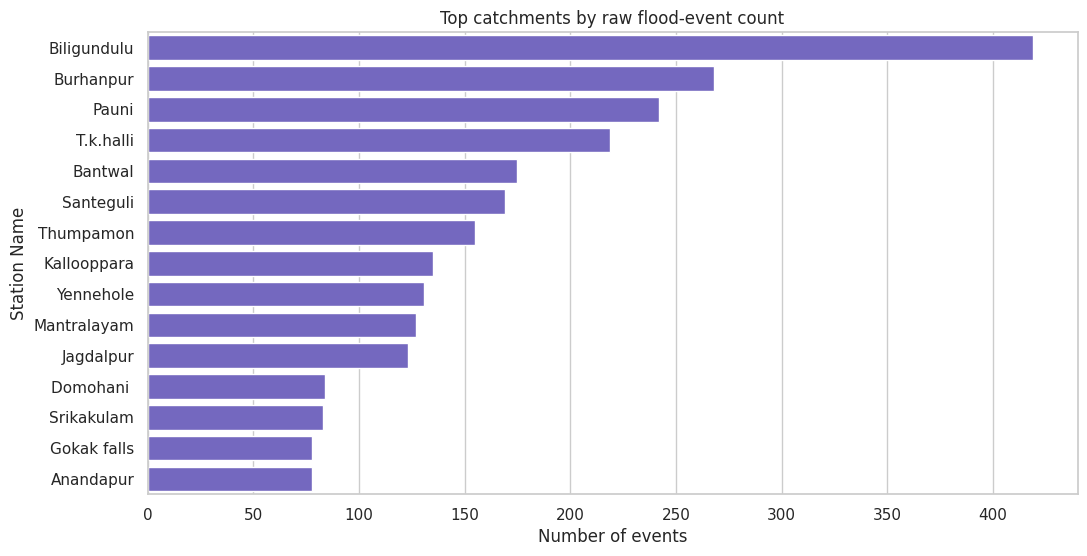

In [ ]:
# Prepare temporal data
events['year'] = events['start_date'].dt.year
events['month'] = events['start_date'].dt.month

# Annual Data & Smoothing
annual = events.groupby('year').size().reset_index(name='event_count')
ev_meta = metadata[metadata['gaugeid'].isin(events['gauge_id'])]
active = {y: ((ev_meta['start_date'].dt.year<=y)&(ev_meta['end_date'].dt.year>=y)).sum() for y in annual['year'].dropna().astype(int)}
annual['active_gauges'] = annual['year'].map(active)
annual['events_per_gauge'] = annual['event_count']/annual['active_gauges']
annual = annual[annual['year']<2020].dropna()   # drop partial year

# Monthly Data for Seasonality
monthly = events.groupby('month').size().reset_index(name='event_count')

# Setup the multi-panel plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Smoothed Annual Trend
x = annual['year'].values
y = annual['events_per_gauge'].values

# Spline interpolation for a smooth line
x_smooth = np.linspace(x.min(), x.max(), 300)
spline = make_interp_spline(x, y, k=3)
y_smooth = spline(x_smooth)

sns.lineplot(x=x_smooth, y=y_smooth, ax=axes[0], color='royalblue', label='Smoothed Trend', linewidth=2)
axes[0].scatter(x, y, color='royalblue', alpha=0.5, s=20, label='Annual Data')
axes[0].set_title('Recorded flood events by year (Smoothed)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Events per Gauge')
axes[0].legend()

# Plot 2: Seasonality (Monthly Distribution)
sns.lineplot(data=monthly, x='month', y='event_count', ax=axes[1], marker='o', color='teal', linewidth=2.5)
axes[1].set_title('Flood Event Seasonality (by Month)')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Total Number of Events')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

plt.tight_layout()
plt.show()

# Catchments with the most recorded flood events
top_raw = events.groupby('gauge_id').size().sort_values(ascending=False).head(15).reset_index(name='event_count')
# Add station names from metadata
meta_names = metadata[['gaugeid', 'station']].rename(columns={'gaugeid': 'gauge_id'})
top_raw = top_raw.merge(meta_names, on='gauge_id', how='left')
# Gauge ID is used when the station name is missing
top_raw['display_name'] = top_raw['station'].fillna(top_raw['gauge_id'])

plt.figure(figsize=(12, 6))
sns.barplot(data=top_raw, x='event_count', y='display_name', color='slateblue')
plt.title('Top catchments by raw flood-event count')
plt.xlabel('Number of events')
plt.ylabel('Station Name')
plt.show()

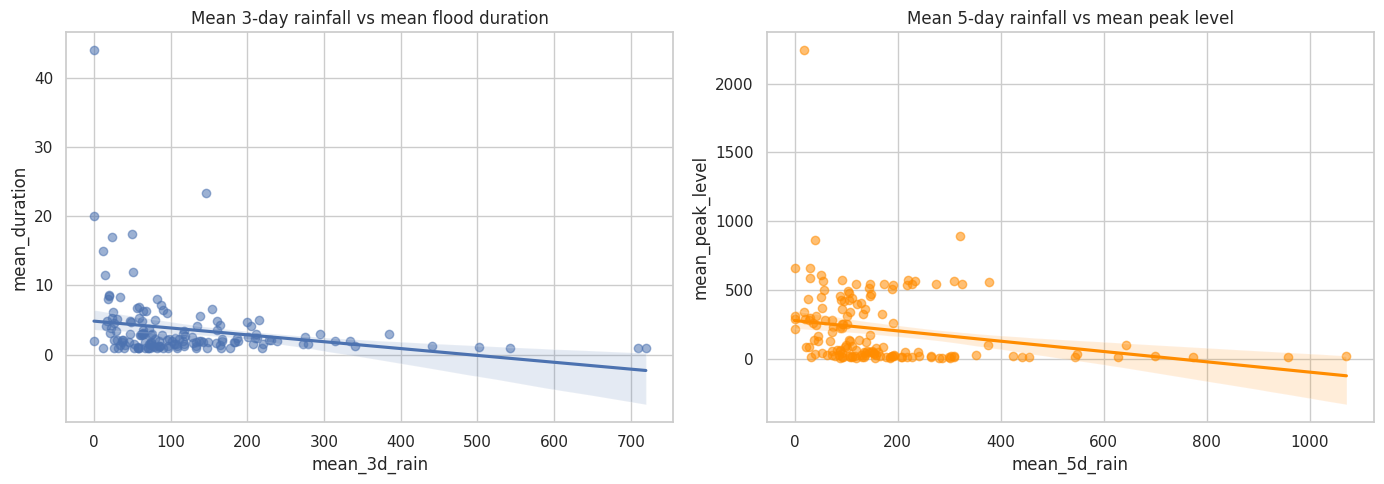

Spearman mean_3d_rain vs mean_duration: rho=-0.288, p=0.0003123
Spearman mean_5d_rain vs mean_peak_level: rho=-0.366, p=2.797e-06
Within-gauge Spearman 5d rain vs peak anomaly: rho=0.094, p=2.999e-10


In [ ]:
rain_plot = rainfall[['eventid','t3d','t5d']].merge(
    events[['eventid','gauge_id','event_duration_days','peak_flood_level_m','flood_type']],
    on='eventid', how='inner')
    # Aggregate rainfall and event data by catchment for an interpretable exploratory comparison.
eda = rain_plot.groupby('gauge_id').agg(
        mean_3d_rain=('t3d', 'mean'),
        mean_5d_rain=('t5d', 'mean'),
        mean_duration=('event_duration_days', 'mean'),
        mean_peak_level=('peak_flood_level_m', 'mean')
    ).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.regplot(data=eda, x='mean_3d_rain', y='mean_duration', ax=axes[0], scatter_kws={'alpha': .55})
axes[0].set_title('Mean 3-day rainfall vs mean flood duration')
sns.regplot(data=eda, x='mean_5d_rain', y='mean_peak_level', ax=axes[1], scatter_kws={'alpha': .55}, color='darkorange')
axes[1].set_title('Mean 5-day rainfall vs mean peak level')
plt.tight_layout()
plt.show()

for x, y in [('mean_3d_rain', 'mean_duration'), ('mean_5d_rain', 'mean_peak_level')]:
        valid = eda[[x, y]].dropna()
        rho, p = spearmanr(valid[x], valid[y])
        print(f'Spearman {x} vs {y}: rho={rho:.3f}, p={p:.4g}')
rain_plot['peak_anom'] = rain_plot['peak_flood_level_m'] - rain_plot.groupby('gauge_id')['peak_flood_level_m'].transform('mean')
valid = rain_plot[['t5d','peak_anom']].dropna()
rho, p = spearmanr(valid['t5d'], valid['peak_anom'])
print(f'Within-gauge Spearman 5d rain vs peak anomaly: rho={rho:.3f}, p={p:.4g}')

## 4. Construct catchment-level hazard indicators

Raw counts are adjusted for the length of the observed record. Peak levels are included as a descriptive hazard indicator; station-relative exceedance is calculated where warning and danger thresholds are available.

In [ ]:
monitoring = events.groupby('gauge_id').agg(event_count=('eventid', 'count')).reset_index()
rec = metadata[['gaugeid', 'start_date', 'end_date']].rename(columns={'gaugeid': 'gauge_id'})
rec['monitoring_years'] = (pd.to_datetime(rec['end_date']) - pd.to_datetime(rec['start_date'])).dt.days / 365.25
monitoring = monitoring.merge(rec[['gauge_id', 'monitoring_years']], on='gauge_id')
monitoring['flood_frequency'] = monitoring['event_count'] / monitoring['monitoring_years']

thr = metadata[['gaugeid', 'warning_level', 'danger_level']].rename(columns={'gaugeid': 'gauge_id'})
events = events.drop(columns=['warning_level', 'danger_level'], errors='ignore').merge(thr, on='gauge_id', how='left')
events['above_danger_m'] = events['peak_flood_level_m'] - events['danger_level']

print(events['above_danger_m'].describe(percentiles=[.5, .9, .99]))

count   4,451.000
mean        4.181
std        56.338
min        -3.320
50%        -0.400
90%         2.590
99%       113.910
max     2,988.200
Name: above_danger_m, dtype: float64


Some events show a peak level more than 50 m away from the gauge's danger level, which is not physically plausible for a river gauge. These are mostly gauges whose recorded peak and danger level appear to be on different datums, plus a few clear recording errors (one peak is 4,485 m). They are set to missing so that they do not distort the exceedance indicator.

In [ ]:
implausible = events['above_danger_m'].abs() > 50
print('Events with implausible level above danger:', implausible.sum(), 'in', events.loc[implausible, 'gauge_id'].nunique(), 'gauges')

bad_gauges = (events[implausible].groupby('gauge_id').size().rename('implausible_events').reset_index()
              .merge(metadata[['gaugeid', 'station']].rename(columns={'gaugeid': 'gauge_id'}), on='gauge_id', how='left')
              .sort_values('implausible_events', ascending=False))
display(bad_gauges.head(10))

events.loc[implausible, 'above_danger_m'] = np.nan
print('Largest remaining value above danger level (m):', round(events['above_danger_m'].max(), 2))

Events with implausible level above danger: 103 in 17 gauges


,gauge_id,implausible_events,station
10,INDOFLOODS-gauge-679,70,Yelli
0,INDOFLOODS-gauge-1050,9,Tufanganj
6,INDOFLOODS-gauge-472,4,Hoshangabad
2,INDOFLOODS-gauge-1086,3,Hasimara
7,INDOFLOODS-gauge-509,2,Mohanpur
12,INDOFLOODS-gauge-833,2,Kukkalthurai
16,INDOFLOODS-gauge-916,2,Singur dam
1,INDOFLOODS-gauge-1056,2,Katwa
4,INDOFLOODS-gauge-346,1,Avershe
8,INDOFLOODS-gauge-626,1,Ujani dam


Largest remaining value above danger level (m): 46.79


In [ ]:
hazard = events.groupby('gauge_id').agg(
    severe_share=('flood_type', lambda s: (s.astype(str).str.lower() == 'severe flood').mean()),
    p95_duration=('event_duration_days', lambda s: s.quantile(.95)),
    p95_above_danger=('above_danger_m', lambda s: s.quantile(.95)),
    p95_peak_level=('peak_flood_level_m', lambda s: s.quantile(.95)),
    mean_duration=('event_duration_days', 'mean'),
    mean_peak_level=('peak_flood_level_m', 'mean')
).reset_index()

rainfall_hazard = rainfall.groupby('gauge_id').agg(
    p95_rain_3d=('t3d', lambda s: s.quantile(.95)),
    p95_rain_5d=('t5d', lambda s: s.quantile(.95)),
    mean_rain_3d=('t3d', 'mean'),
    mean_rain_5d=('t5d', 'mean')
).reset_index()

hazard_data = monitoring.merge(hazard, on='gauge_id', how='inner').merge(rainfall_hazard, on='gauge_id', how='inner')
hazard_data = hazard_data.merge(thr, on='gauge_id', how='left')

print('Hazard records:', len(hazard_data))
display(hazard_data.query('monitoring_years >= 15 and event_count >= 20')
        .sort_values('flood_frequency', ascending=False).head(10))

Hazard records: 155


,gauge_id,event_count,monitoring_years,flood_frequency,severe_share,p95_duration,p95_above_danger,p95_peak_level,mean_duration,mean_peak_level,p95_rain_3d,p95_rain_5d,mean_rain_3d,mean_rain_5d,warning_level,danger_level
48,INDOFLOODS-gauge-394,419,48.742,8.596,0.079,22.000,0.402,262.402,6.112,260.168,60.115,88.149,24.378,35.661,259.200,262.000
83,INDOFLOODS-gauge-560,268,46.930,5.711,0.276,11.000,7.433,228.412,3.571,220.823,144.288,176.213,63.274,88.329,218.000,220.980
36,INDOFLOODS-gauge-349,169,31.986,5.284,0.089,11.000,0.472,17.472,3.586,15.231,316.046,488.092,160.882,264.387,14.000,17.000
38,INDOFLOODS-gauge-361,219,41.958,5.220,0.767,11.100,2.064,584.564,3.795,583.064,57.778,74.152,21.871,29.214,582.250,582.500
85,INDOFLOODS-gauge-571,242,55.680,4.346,0.595,21.000,5.733,233.463,6.764,228.938,109.393,145.475,56.477,74.403,226.730,227.730
44,INDOFLOODS-gauge-372,73,16.862,4.329,0.041,6.000,-0.316,6.184,2.423,4.756,331.228,450.495,186.010,279.661,3.500,6.500
50,INDOFLOODS-gauge-396,131,30.842,4.247,0.069,4.000,0.055,23.055,1.588,21.401,511.382,838.093,278.520,423.503,20.500,23.000
67,INDOFLOODS-gauge-427,135,34.938,3.864,0.363,5.300,2.015,8.015,2.407,6.038,206.224,289.187,106.188,155.388,5.000,6.000
69,INDOFLOODS-gauge-429,155,42.431,3.653,0.329,9.300,2.009,12.009,3.123,10.002,151.363,206.457,64.555,92.989,9.000,10.000
40,INDOFLOODS-gauge-364,175,49.569,3.530,0.223,6.300,1.603,10.603,2.606,8.234,365.248,559.150,200.784,309.654,7.000,9.000


## 5. Join hazard with catchment exposure and vulnerability

In [ ]:
risk_data = hazard_data.merge(catchments, on='gauge_id', how='inner', suffixes=('', '_catchment'))
print('Final catchment records:', risk_data.shape[0])
print('Final variable count:', risk_data.shape[1])

required_risk_columns = [
        'flood_frequency', 'severe_share', 'p95_duration', 'p95_rain_3d',
        'p95_rain_5d', 'p95_above_danger', 'population_density',
        'urban_percentage', 'road_density', 'night_light', '2015_gdp_pc_ppp', '2015_hdi'
    ]
available = [c for c in required_risk_columns if c in risk_data.columns]
missing = [c for c in required_risk_columns if c not in risk_data.columns]
print('Available score variables:', available)
if missing:
        print('Not available and omitted:', missing)
display(risk_data[available].isna().mean().mul(100).round(2).sort_values(ascending=False).to_frame('missing_percent'))

Final catchment records: 155
Final variable count: 124
Available score variables: ['flood_frequency', 'severe_share', 'p95_duration', 'p95_rain_3d', 'p95_rain_5d', 'p95_above_danger', 'population_density', 'urban_percentage', 'road_density', 'night_light', '2015_gdp_pc_ppp', '2015_hdi']


,missing_percent
p95_above_danger,3.230
p95_duration,1.290
severe_share,0.000
flood_frequency,0.000
p95_rain_3d,0.000
p95_rain_5d,0.000
population_density,0.000
urban_percentage,0.000
road_density,0.000
night_light,0.000


## 6. Calculate the composite risk-priority index

Each indicator is converted to a percentile score. The hazard and exposure scores are the means of their components. The main final score is their geometric mean:

$$R_i = \sqrt{H_i \times E_i}$$

This prevents high exposure with almost no hazard, or high hazard with almost no exposure, from automatically dominating the ranking.

In [ ]:
risk_data = risk_data[(risk_data.event_count >= 20) & (risk_data.monitoring_years >= 15)].copy()
print('Catchments scored:', len(risk_data))
hazard_columns = [c for c in [
        'flood_frequency', 'severe_share', 'p95_duration'
            ] if c in risk_data.columns]

exposure_columns = [c for c in [
        'population_density', 'urban_percentage', 'road_density',
        'night_light', '2015_gdp_pc_ppp'
    ] if c in risk_data.columns]

def percentile_score(series):
        # Missing values are replaced by the median before ranking
        filled = series.fillna(series.median())
        return filled.rank(pct=True)

for col in hazard_columns + exposure_columns:
        risk_data[col + '_score'] = percentile_score(risk_data[col])

risk_data['hazard_score'] = risk_data[[c + '_score' for c in hazard_columns]].mean(axis=1)
risk_data['hdi_vuln_score'] = 1 - percentile_score(risk_data['2015_hdi'])        # low HDI = more vulnerable
risk_data['pop_count_score'] = percentile_score(np.log1p(risk_data['population_count']))
exp_cols = [c + '_score' for c in exposure_columns] + ['hdi_vuln_score', 'pop_count_score']
risk_data['exposure_score'] = risk_data[exp_cols].mean(axis=1)
risk_data['risk_priority_score'] = np.sqrt(risk_data['hazard_score'] * risk_data['exposure_score'])
risk_data['risk_percentile'] = risk_data['risk_priority_score'].rank(pct=True)
risk_data['priority_category'] = pd.cut(
        risk_data['risk_percentile'],
        bins=[0, .4, .8, .9, 1],
        labels=['Low', 'Moderate', 'High', 'Very high'],
        include_lowest=True
    )


ranked = risk_data.sort_values('risk_priority_score', ascending=False).reset_index(drop=True)
ranked.insert(0, 'rank', ranked.index + 1)
result_columns = ['rank', 'gauge_id', 'event_count', 'flood_frequency', 'severe_share', 'hazard_score', 'exposure_score', 'risk_priority_score', 'priority_category']
names = metadata[['gaugeid','station','basin','state']].rename(columns={'gaugeid':'gauge_id'})
ranked = ranked.merge(names, on='gauge_id', how='left')
result_columns = ['rank','gauge_id','station','basin','state'] + result_columns[2:]
display(ranked[result_columns].head(20))
print(risk_data[[c+'_score' for c in hazard_columns+exposure_columns]].corr(method='spearman').round(2))
rho, p = spearmanr(risk_data['hazard_score'], risk_data['exposure_score']); print('H vs E:', round(rho,3), p)

Catchments scored: 46


,rank,gauge_id,station,basin,state,event_count,flood_frequency,severe_share,hazard_score,exposure_score,risk_priority_score,priority_category
0,1,INDOFLOODS-gauge-319,T. bekkupe,Cauvery,Karnataka,33,1.981,0.727,0.714,0.807,0.759,Very high
1,2,INDOFLOODS-gauge-643,Terwad (seasonal),Krishna,Maharashtra,69,1.693,0.420,0.710,0.764,0.737,Very high
2,3,INDOFLOODS-gauge-679,Yelli,Godavari,Maharashtra,70,1.667,1.000,0.870,0.599,0.722,Very high
3,4,INDOFLOODS-gauge-852,Kuzhithurai,West Flowing Rivers From Tadri to Kanyakumari,Tamil Nadu,37,1.891,0.405,0.768,0.674,0.719,Very high
4,5,INDOFLOODS-gauge-394,Biligundulu,Cauvery,Karnataka,419,8.596,0.079,0.696,0.733,0.714,Very high
5,6,INDOFLOODS-gauge-361,T.k.halli,Cauvery,Karnataka,219,5.220,0.767,0.884,0.565,0.707,High
6,7,INDOFLOODS-gauge-571,Pauni,Godavari,Maharashtra,242,4.346,0.595,0.913,0.500,0.676,High
7,8,INDOFLOODS-gauge-427,Kallooppara,West Flowing Rivers From Tadri to Kanyakumari,Kerala,135,3.864,0.363,0.612,0.618,0.615,High
8,9,INDOFLOODS-gauge-681,Samdoli (seasonal),Krishna,Maharashtra,26,0.469,0.577,0.572,0.643,0.607,High
9,10,INDOFLOODS-gauge-397,Gokak falls,Krishna,Karnataka,78,1.622,0.346,0.594,0.602,0.598,High


                          flood_frequency_score  severe_share_score  \
flood_frequency_score                     1.000              -0.190   
severe_share_score                       -0.190               1.000   
p95_duration_score                        0.360               0.060   
population_density_score                 -0.230               0.150   
urban_percentage_score                   -0.140               0.180   
road_density_score                       -0.150               0.110   
night_light_score                        -0.270               0.210   
2015_gdp_pc_ppp_score                    -0.320               0.030   

                          p95_duration_score  population_density_score  \
flood_frequency_score                  0.360                    -0.230   
severe_share_score                     0.060                     0.150   
p95_duration_score                     1.000                     0.240   
population_density_score               0.240                    

## 7. Hazard-versus-exposure quadrants

The median hazard score and the median exposure score split the scored catchments into four quadrants. Catchments in the high-hazard, high-exposure quadrant form the first priority list.

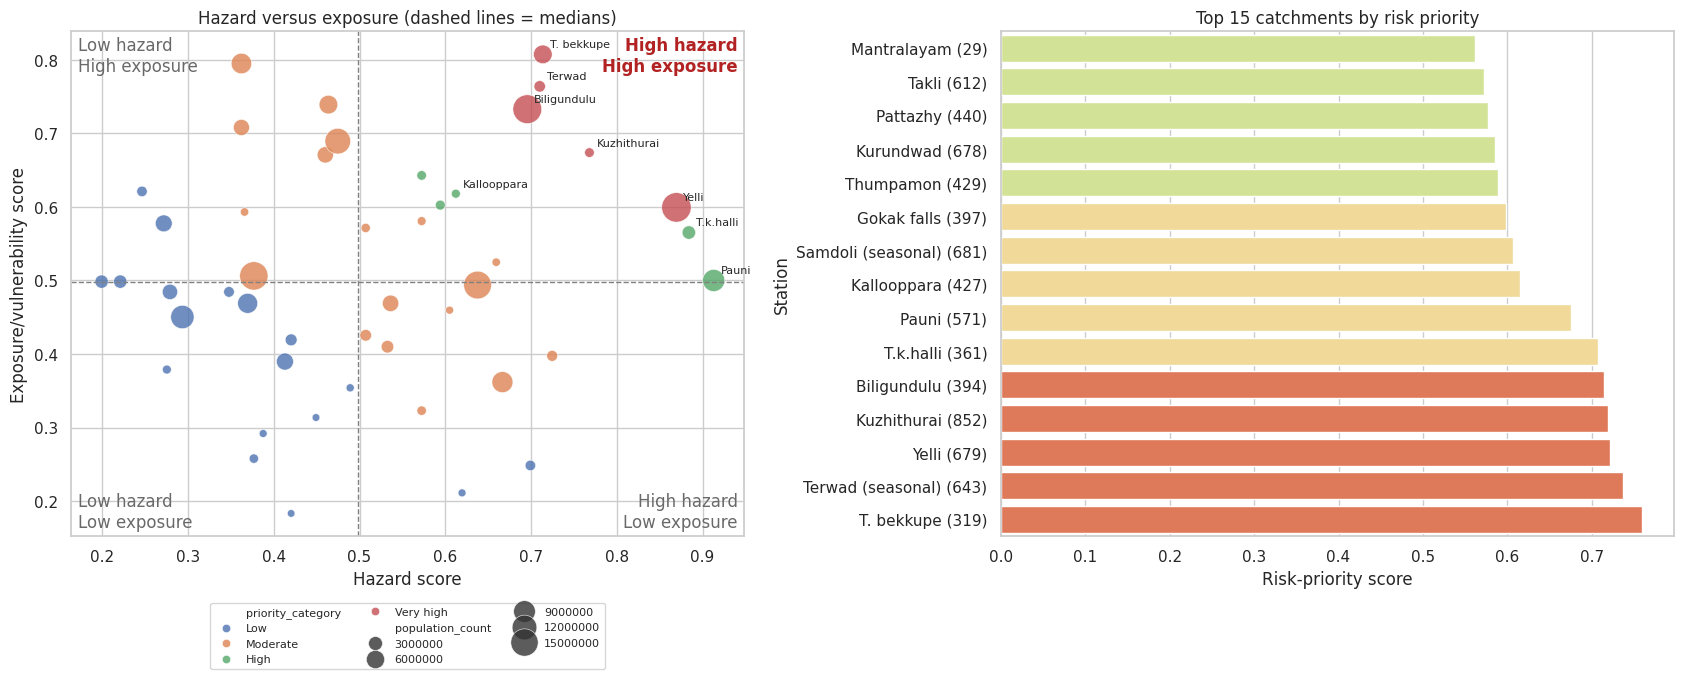

In [ ]:
h_med = risk_data['hazard_score'].median()
e_med = risk_data['exposure_score'].median()

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

sns.scatterplot(data=risk_data, x='hazard_score', y='exposure_score', hue='priority_category',
                size='population_count', sizes=(30, 450), alpha=.8, ax=axes[0])
axes[0].axvline(h_med, color='grey', linestyle='--', linewidth=1)
axes[0].axhline(e_med, color='grey', linestyle='--', linewidth=1)
for _, row in risk_data.nlargest(8, 'risk_priority_score').iterrows():
    axes[0].annotate(row['station_label'].split(' (')[0], (row['hazard_score'], row['exposure_score']),
                     xytext=(5, 5), textcoords='offset points', fontsize=8)
axes[0].text(0.99, 0.99, 'High hazard\nHigh exposure', transform=axes[0].transAxes, ha='right', va='top', fontweight='bold', color='firebrick')
axes[0].text(0.01, 0.99, 'Low hazard\nHigh exposure', transform=axes[0].transAxes, ha='left', va='top', color='dimgrey')
axes[0].text(0.99, 0.01, 'High hazard\nLow exposure', transform=axes[0].transAxes, ha='right', va='bottom', color='dimgrey')
axes[0].text(0.01, 0.01, 'Low hazard\nLow exposure', transform=axes[0].transAxes, ha='left', va='bottom', color='dimgrey')
sns.move_legend(axes[0], 'upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8)
axes[0].set_title('Hazard versus exposure (dashed lines = medians)')
axes[0].set_xlabel('Hazard score')
axes[0].set_ylabel('Exposure/vulnerability score')

top = ranked.head(15).sort_values('risk_priority_score')
sns.barplot(data=top, x='risk_priority_score', y='station_label', hue='priority_category',
            dodge=False, legend=False, ax=axes[1], palette='RdYlGn_r')
axes[1].set_title('Top 15 catchments by risk priority')
axes[1].set_xlabel('Risk-priority score')
axes[1].set_ylabel('Station')

plt.tight_layout()
plt.show()

In [ ]:
risk_data['quadrant'] = np.select(
    [(risk_data['hazard_score'] >= h_med) & (risk_data['exposure_score'] >= e_med),
     (risk_data['hazard_score'] >= h_med) & (risk_data['exposure_score'] < e_med),
     (risk_data['hazard_score'] < h_med) & (risk_data['exposure_score'] >= e_med)],
    ['High hazard, high exposure', 'High hazard, low exposure', 'Low hazard, high exposure'],
    default='Low hazard, low exposure')

display(risk_data['quadrant'].value_counts().to_frame('catchments'))

priority_quadrant = risk_data.loc[risk_data['quadrant'] == 'High hazard, high exposure', 'gauge_id']
print('Catchments in the high-hazard, high-exposure quadrant:', len(priority_quadrant))
display(ranked[ranked['gauge_id'].isin(priority_quadrant)][result_columns])

,catchments
quadrant,
"High hazard, high exposure",13
"Low hazard, low exposure",12
"Low hazard, high exposure",11
"High hazard, low exposure",10


Catchments in the high-hazard, high-exposure quadrant: 13


,rank,gauge_id,station,basin,state,event_count,flood_frequency,severe_share,hazard_score,exposure_score,risk_priority_score,priority_category
0,1,INDOFLOODS-gauge-319,T. bekkupe,Cauvery,Karnataka,33,1.981,0.727,0.714,0.807,0.759,Very high
1,2,INDOFLOODS-gauge-643,Terwad (seasonal),Krishna,Maharashtra,69,1.693,0.420,0.710,0.764,0.737,Very high
2,3,INDOFLOODS-gauge-679,Yelli,Godavari,Maharashtra,70,1.667,1.000,0.870,0.599,0.722,Very high
3,4,INDOFLOODS-gauge-852,Kuzhithurai,West Flowing Rivers From Tadri to Kanyakumari,Tamil Nadu,37,1.891,0.405,0.768,0.674,0.719,Very high
4,5,INDOFLOODS-gauge-394,Biligundulu,Cauvery,Karnataka,419,8.596,0.079,0.696,0.733,0.714,Very high
5,6,INDOFLOODS-gauge-361,T.k.halli,Cauvery,Karnataka,219,5.220,0.767,0.884,0.565,0.707,High
6,7,INDOFLOODS-gauge-571,Pauni,Godavari,Maharashtra,242,4.346,0.595,0.913,0.500,0.676,High
7,8,INDOFLOODS-gauge-427,Kallooppara,West Flowing Rivers From Tadri to Kanyakumari,Kerala,135,3.864,0.363,0.612,0.618,0.615,High
8,9,INDOFLOODS-gauge-681,Samdoli (seasonal),Krishna,Maharashtra,26,0.469,0.577,0.572,0.643,0.607,High
9,10,INDOFLOODS-gauge-397,Gokak falls,Krishna,Karnataka,78,1.622,0.346,0.594,0.602,0.598,High


## 8. Catchment typology

K-means clustering on the hazard and exposure scores groups catchments with a similar risk profile. The groups are named from their average hazard and exposure, and the raw indicators are shown to describe what each group looks like.

In [ ]:
cluster_inputs = risk_data[['hazard_score', 'exposure_score']]

for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(cluster_inputs)
    print(f'k = {k}: silhouette score = {silhouette_score(cluster_inputs, labels):.3f}')

k = 2: silhouette score = 0.358
k = 3: silhouette score = 0.375
k = 4: silhouette score = 0.350
k = 5: silhouette score = 0.374
k = 6: silhouette score = 0.404


In [ ]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(cluster_inputs)
risk_data['cluster'] = kmeans.labels_

def level(score):
    if score < 0.4:
        return 'low'
    if score > 0.6:
        return 'high'
    return 'moderate'

centres = pd.DataFrame(kmeans.cluster_centers_, columns=['hazard', 'exposure'])
centres['catchment_type'] = [f'{level(h).capitalize()} hazard, {level(e)} exposure'
                             for h, e in zip(centres['hazard'], centres['exposure'])]
risk_data['catchment_type'] = risk_data['cluster'].map(centres['catchment_type'])

type_summary = risk_data.groupby('catchment_type').agg(
    catchments=('gauge_id', 'count'),
    mean_hazard=('hazard_score', 'mean'),
    mean_exposure=('exposure_score', 'mean'),
    median_flood_frequency=('flood_frequency', 'median'),
    median_severe_share=('severe_share', 'median'),
    median_population_density=('population_density', 'median'),
    median_night_light=('night_light', 'median'),
    mean_risk_score=('risk_priority_score', 'mean')
).sort_values('mean_risk_score', ascending=False)
display(type_summary)

,catchments,mean_hazard,mean_exposure,median_flood_frequency,median_severe_share,median_population_density,median_night_light,mean_risk_score
catchment_type,,,,,,,,
"High hazard, moderate exposure",9,0.748,0.508,2.237,0.512,330.541,2.136,0.614
"Moderate hazard, high exposure",13,0.546,0.686,0.852,0.363,452.848,5.142,0.608
"Moderate hazard, low exposure",13,0.494,0.331,1.709,0.301,196.803,0.875,0.398
"Low hazard, moderate exposure",11,0.295,0.506,0.726,0.143,320.351,2.109,0.383


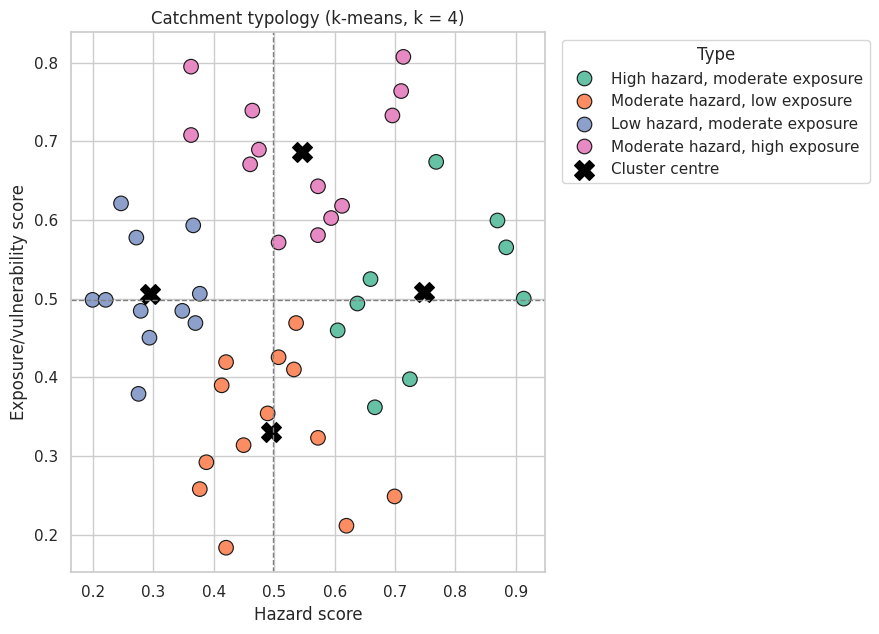

In [ ]:
plt.figure(figsize=(9, 6.5))
sns.scatterplot(data=risk_data, x='hazard_score', y='exposure_score', hue='catchment_type',
                s=110, palette='Set2', edgecolor='k')
plt.scatter(centres['hazard'], centres['exposure'], marker='X', s=200, color='black', label='Cluster centre')
plt.axvline(h_med, color='grey', linestyle='--', linewidth=1)
plt.axhline(e_med, color='grey', linestyle='--', linewidth=1)
plt.xlabel('Hazard score')
plt.ylabel('Exposure/vulnerability score')
plt.title('Catchment typology (k-means, k = 4)')
plt.legend(title='Type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 9. Compare alternative rankings

In [ ]:
rank_comparison = risk_data[['gauge_id', 'event_count', 'flood_frequency', 'hazard_score', 'risk_priority_score']].copy()
rank_comparison['raw_count_rank'] = rank_comparison['event_count'].rank(method='min', ascending=False).astype(int)
rank_comparison['frequency_rank'] = rank_comparison['flood_frequency'].rank(method='min', ascending=False).astype(int)
rank_comparison['hazard_rank'] = rank_comparison['hazard_score'].rank(method='min', ascending=False).astype(int)
rank_comparison['risk_rank'] = rank_comparison['risk_priority_score'].rank(method='min', ascending=False).astype(int)
rank_comparison['risk_minus_count_rank'] = rank_comparison['risk_rank'] - rank_comparison['raw_count_rank']
rank_comparison['moved'] = np.where(rank_comparison['risk_minus_count_rank'] < 0, 'up vs count', 'down vs count')
display(rank_comparison.sort_values('risk_rank').head(20))

for a, b in [('event_count', 'risk_priority_score'), ('flood_frequency', 'risk_priority_score'), ('hazard_score', 'risk_priority_score')]:
        valid = rank_comparison[[a, b]].dropna()
        rho, p = spearmanr(valid[a], valid[b])
        print(f'Spearman {a} vs {b}: rho={rho:.3f}, p={p:.4g}')

,gauge_id,event_count,flood_frequency,hazard_score,risk_priority_score,raw_count_rank,frequency_rank,hazard_rank,risk_rank,risk_minus_count_rank,moved
29,INDOFLOODS-gauge-319,33,1.981,0.714,0.759,31,14,6,1,-30,up vs count
99,INDOFLOODS-gauge-643,69,1.693,0.710,0.737,17,18,7,2,-15,up vs count
109,INDOFLOODS-gauge-679,70,1.667,0.870,0.722,16,19,3,3,-13,up vs count
133,INDOFLOODS-gauge-852,37,1.891,0.768,0.719,25,15,4,4,-21,up vs count
48,INDOFLOODS-gauge-394,419,8.596,0.696,0.714,1,1,9,5,4,down vs count
38,INDOFLOODS-gauge-361,219,5.220,0.884,0.707,4,4,2,6,2,down vs count
85,INDOFLOODS-gauge-571,242,4.346,0.913,0.676,3,5,1,7,4,down vs count
67,INDOFLOODS-gauge-427,135,3.864,0.612,0.615,8,8,14,8,0,down vs count
110,INDOFLOODS-gauge-681,26,0.469,0.572,0.607,39,45,17,9,-30,up vs count
51,INDOFLOODS-gauge-397,78,1.622,0.594,0.598,13,20,16,10,-3,up vs count


Spearman event_count vs risk_priority_score: rho=0.271, p=0.0685
Spearman flood_frequency vs risk_priority_score: rho=0.234, p=0.1173
Spearman hazard_score vs risk_priority_score: rho=0.745, p=2.937e-09


## 10. Sensitivity analysis

The main score uses a geometric mean. This section tests weighted arithmetic scores to see whether the highest-priority catchments are stable.

Hazard-focused top 10: Biligundulu (394), Kallooppara (427), Kuzhithurai (852), Pauni (571), Samdoli (seasonal) (681), T. bekkupe (319), T.k.halli (361), Terwad (seasonal) (643), Thumpamon (429), Yelli (679)
Balanced top 10: Biligundulu (394), Kallooppara (427), Kurundwad (678), Kuzhithurai (852), Pauni (571), Samdoli (seasonal) (681), T. bekkupe (319), T.k.halli (361), Terwad (seasonal) (643), Yelli (679)
Exposure-focused top 10: Biligundulu (394), Dhond (640), Kallooppara (427), Kurundwad (678), Kuzhithurai (852), Pauni (571), T. bekkupe (319), T.k.halli (361), Terwad (seasonal) (643), Yelli (679)

Top-10 overlap:
Balanced vs Hazard-focused : 9 of 10
Balanced vs Exposure-focused : 9 of 10
Exposure-focused vs Hazard-focused : 8 of 10


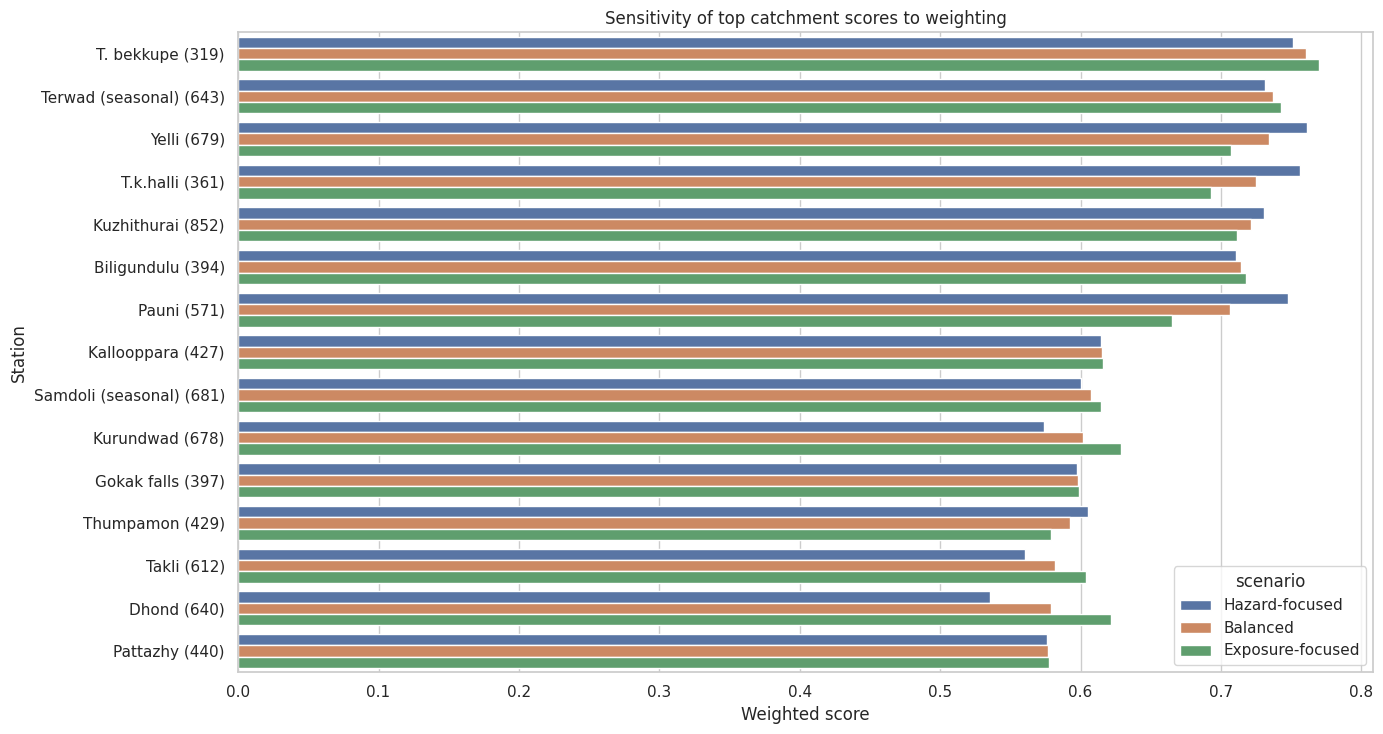

In [ ]:
scenarios = {'Hazard-focused': (.60, .40), 'Balanced': (.50, .50), 'Exposure-focused': (.40, .60)}

sensitivity = risk_data[['gauge_id', 'station_label', 'hazard_score', 'exposure_score']].copy()
for name, (wh, we) in scenarios.items():
    sensitivity[name] = wh * sensitivity['hazard_score'] + we * sensitivity['exposure_score']

top_sets = {name: set(sensitivity.nlargest(10, name)['gauge_id']) for name in scenarios}
for name, members in top_sets.items():
    names_in_top = sensitivity.loc[sensitivity['gauge_id'].isin(members), 'station_label']
    print(name, 'top 10:', ', '.join(sorted(names_in_top)))

print('\nTop-10 overlap:')
for a in scenarios:
    for b in scenarios:
        if a < b:
            print(a, 'vs', b, ':', len(top_sets[a] & top_sets[b]), 'of 10')

plot_sensitivity = sensitivity.melt(id_vars=['gauge_id', 'station_label'], value_vars=list(scenarios),
                                    var_name='scenario', value_name='score')
top_for_plot = sensitivity.nlargest(15, 'Balanced')

plt.figure(figsize=(14, 7.5))
sns.barplot(data=plot_sensitivity[plot_sensitivity['gauge_id'].isin(top_for_plot['gauge_id'])],
            x='score', y='station_label', hue='scenario', order=top_for_plot['station_label'])
plt.title('Sensitivity of top catchment scores to weighting')
plt.xlabel('Weighted score')
plt.ylabel('Station')
plt.tight_layout()
plt.show()

The next cell tests the geometric-mean index with random indicator weights. In each of 1,000 draws the weights within the hazard group and within the exposure group are sampled at random, and the share of draws in which a catchment reaches the top 10 is recorded.

In [ ]:
rng = np.random.default_rng(42)
Hm = risk_data[[c+'_score' for c in hazard_columns]].values
Em = risk_data[exp_cols].values
hits = np.zeros(len(risk_data))
for _ in range(1000):
    r = np.sqrt((Hm @ rng.dirichlet(np.ones(Hm.shape[1]))) * (Em @ rng.dirichlet(np.ones(Em.shape[1]))))
    hits[np.argsort(-r)[:10]] += 1
stab = pd.DataFrame({'gauge_id': risk_data['gauge_id'].values, 'top10_freq': hits/1000}).sort_values('top10_freq', ascending=False)
display(stab.head(15))

,gauge_id,top10_freq
31,INDOFLOODS-gauge-643,0.985
4,INDOFLOODS-gauge-319,0.982
43,INDOFLOODS-gauge-852,0.981
8,INDOFLOODS-gauge-361,0.957
34,INDOFLOODS-gauge-679,0.956
25,INDOFLOODS-gauge-571,0.792
12,INDOFLOODS-gauge-394,0.780
17,INDOFLOODS-gauge-427,0.491
35,INDOFLOODS-gauge-681,0.487
33,INDOFLOODS-gauge-678,0.348


## 11. Monte Carlo simulation of future flood hazard

The index ranks catchments from a historical record that is short for many gauges, and the number of floods in any record is partly a matter of chance. The simulation asks whether the priority list would survive a different draw of history.

For each scored catchment, 5,000 possible futures are simulated:

1. The yearly flood rate is drawn from a gamma distribution built from the observed number of events and the years monitored, so catchments with short records have more uncertain rates.
2. The number of floods over the horizon is drawn from a Poisson distribution at that rate.
3. The share of floods that are severe is drawn from a beta distribution built from the observed severe and non-severe events.
4. Simulated severe floods are multiplied by the catchment's exposure score to give an expected impact.
5. Catchments are re-ranked on expected impact in every simulated future.

The share of futures in which a catchment stays in the top 10 shows how robust its priority status is.

In [ ]:
HORIZON_YEARS = 10
N_SIMULATIONS = 5000
TOP_N = 10

sim_data = risk_data.reset_index(drop=True)

severe_flag = (events['flood_type'].astype(str).str.lower() == 'severe flood').astype(int)
severe_counts = severe_flag.groupby(events['gauge_id']).agg(['sum', 'count'])
severe_counts.columns = ['severe_events', 'all_events']

def simulate_severe_floods(data, horizon_years, n_sim, seed=42):
    rng = np.random.default_rng(seed)
    draws = np.zeros((len(data), n_sim))
    for i, row in enumerate(data.itertuples()):
        severe = severe_counts.loc[row.gauge_id, 'severe_events']
        total = severe_counts.loc[row.gauge_id, 'all_events']
        yearly_rate = rng.gamma(row.event_count + 0.5, 1 / row.monitoring_years, size=n_sim)
        n_floods = rng.poisson(yearly_rate * horizon_years)
        severe_share = rng.beta(severe + 1, total - severe + 1, size=n_sim)
        draws[i] = rng.binomial(n_floods, severe_share)
    return draws

severe_draws = simulate_severe_floods(sim_data, HORIZON_YEARS, N_SIMULATIONS)
print('Simulated severe-flood counts:', severe_draws.shape, '(catchments x simulations)')

Simulated severe-flood counts: (46, 5000) (catchments x simulations)


In [ ]:
impact = severe_draws * sim_data['exposure_score'].values[:, None]
sim_ranks = pd.DataFrame(impact).rank(ascending=False, method='first')

sim = pd.DataFrame({
    'gauge_id': sim_data['gauge_id'],
    'expected_severe_floods': severe_draws.mean(axis=1),
    'severe_p05': np.percentile(severe_draws, 5, axis=1),
    'severe_p95': np.percentile(severe_draws, 95, axis=1),
    'prob_severe_flood': (severe_draws >= 1).mean(axis=1),
    'expected_impact': impact.mean(axis=1),
    'median_sim_rank': sim_ranks.median(axis=1),
    'rank_p05': sim_ranks.quantile(.05, axis=1),
    'rank_p95': sim_ranks.quantile(.95, axis=1),
    'prob_top10': (sim_ranks <= TOP_N).mean(axis=1)
})

index_info = ranked[['gauge_id', 'rank', 'station', 'state', 'priority_category']].rename(columns={'rank': 'index_rank'})
sim = sim.merge(index_info, on='gauge_id', how='left')
sim = sim.merge(risk_data[['gauge_id', 'exposure_score', 'catchment_type']], on='gauge_id', how='left')
sim['label'] = sim['station'].fillna(sim['gauge_id']) + ' (' + sim['gauge_id'].str.extract(r'(\d+)$')[0] + ')'

show_cols = ['label', 'state', 'index_rank', 'median_sim_rank', 'rank_p05', 'rank_p95',
             'prob_top10', 'expected_severe_floods', 'prob_severe_flood']
display(sim.sort_values('median_sim_rank')[show_cols].head(15))

rho, p = spearmanr(sim['index_rank'], sim['median_sim_rank'])
print(f'Index rank versus median simulated rank: Spearman rho = {rho:.3f}, p = {p:.4g}')

,label,state,index_rank,median_sim_rank,rank_p05,rank_p95,prob_top10,expected_severe_floods,prob_severe_flood
8,T.k.halli (361),Karnataka,6,1.000,1.000,1.000,1.000,40.073,1.000
25,Pauni (571),Maharashtra,7,2.000,2.000,5.000,0.999,25.977,1.000
4,T. bekkupe (319),Karnataka,1,3.000,2.000,7.000,0.987,14.378,1.000
34,Yelli (679),Maharashtra,3,4.000,2.000,8.000,0.987,16.484,1.000
17,Kallooppara (427),Kerala,8,5.000,2.000,10.000,0.960,14.181,1.000
19,Thumpamon (429),Kerala,11,7.000,4.000,15.000,0.819,12.131,1.000
12,Biligundulu (394),Karnataka,5,9.000,5.000,22.000,0.580,6.960,0.999
31,Terwad (seasonal) (643),Maharashtra,2,9.000,4.000,21.000,0.640,7.203,0.999
43,Kuzhithurai (852),Tamil Nadu,4,9.000,4.000,23.000,0.606,7.893,0.998
0,Jagdalpur (130),Chhattisgarh,18,11.000,6.000,20.000,0.494,11.473,1.000


Index rank versus median simulated rank: Spearman rho = 0.792, p = 5.609e-11


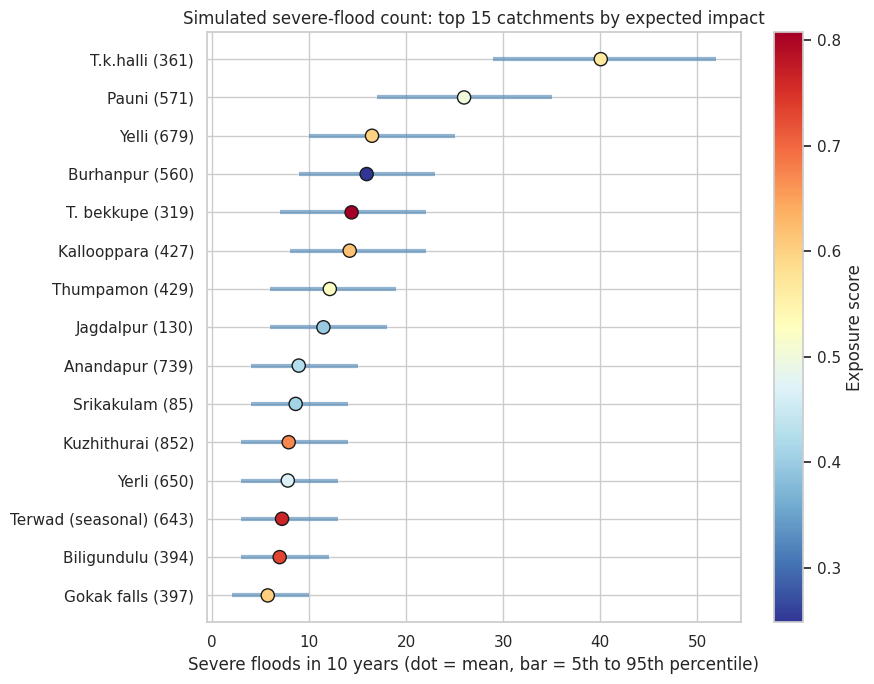

In [ ]:
top_sim = sim.nlargest(15, 'expected_impact').sort_values('expected_severe_floods')
pos = np.arange(len(top_sim))

fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(pos, top_sim['severe_p05'], top_sim['severe_p95'], color='steelblue', linewidth=3, alpha=.6)
points = ax.scatter(top_sim['expected_severe_floods'], pos, c=top_sim['exposure_score'], cmap='RdYlBu_r',
                    s=90, edgecolor='k', zorder=3)
ax.set_yticks(pos)
ax.set_yticklabels(top_sim['label'])
plt.colorbar(points, label='Exposure score')
ax.set_xlabel(f'Severe floods in {HORIZON_YEARS} years (dot = mean, bar = 5th to 95th percentile)')
ax.set_title('Simulated severe-flood count: top 15 catchments by expected impact')
plt.tight_layout()
plt.show()

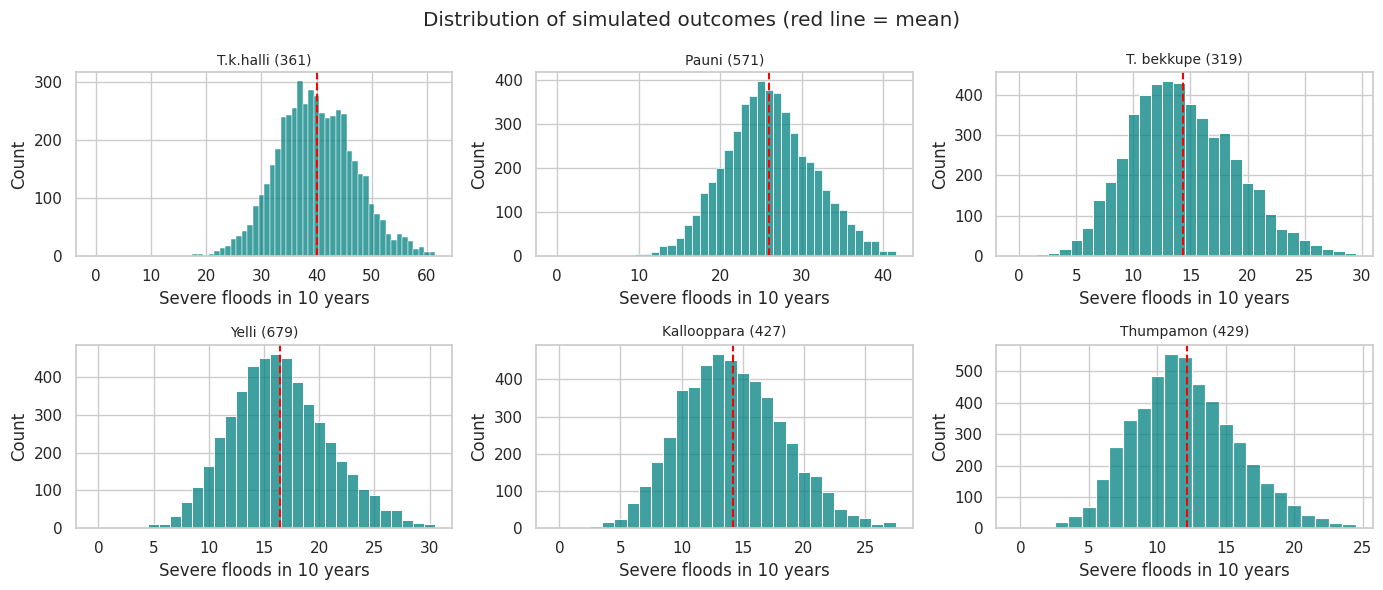

In [ ]:
top_six = sim.nlargest(6, 'expected_impact').index

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, i in zip(axes.ravel(), top_six):
    upper = int(np.percentile(severe_draws[i], 99.5))
    sns.histplot(severe_draws[i], bins=np.arange(0, upper + 2) - .5, ax=ax, color='teal')
    ax.axvline(severe_draws[i].mean(), color='red', linestyle='--')
    ax.set_title(sim.loc[i, 'label'], fontsize=10)
    ax.set_xlabel(f'Severe floods in {HORIZON_YEARS} years')
plt.suptitle('Distribution of simulated outcomes (red line = mean)')
plt.tight_layout()
plt.show()

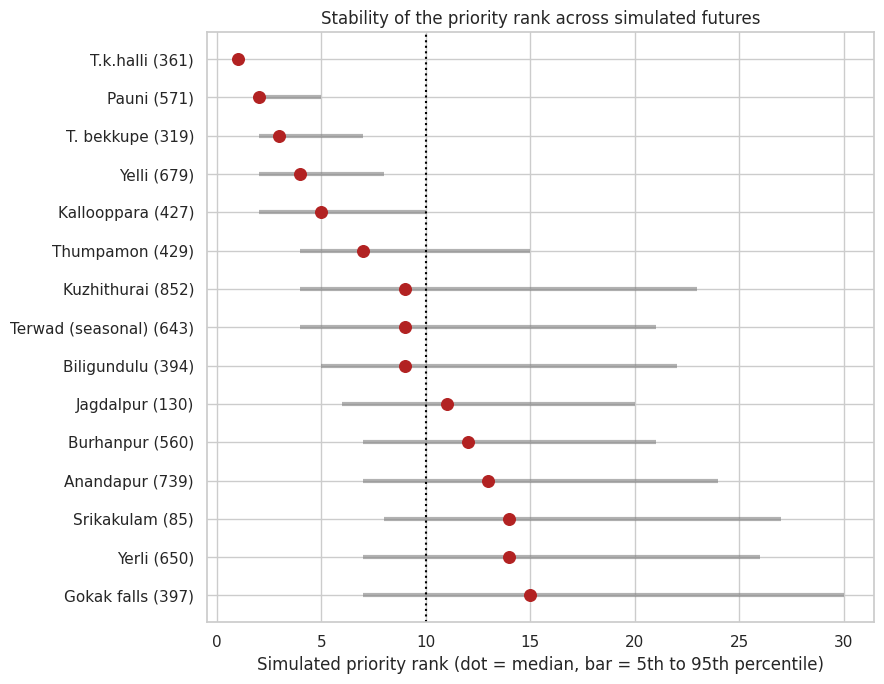

In [ ]:
stable = sim.nsmallest(15, 'median_sim_rank').sort_values('median_sim_rank', ascending=False)
pos = np.arange(len(stable))

fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(pos, stable['rank_p05'], stable['rank_p95'], color='grey', linewidth=3, alpha=.6)
ax.scatter(stable['median_sim_rank'], pos, color='firebrick', s=70, zorder=3)
ax.axvline(TOP_N, linestyle=':', color='black')
ax.set_yticks(pos)
ax.set_yticklabels(stable['label'])
ax.set_xlabel('Simulated priority rank (dot = median, bar = 5th to 95th percentile)')
ax.set_title('Stability of the priority rank across simulated futures')
plt.tight_layout()
plt.show()

### Robust priority list

A catchment is a **robust priority** when it is in the index top 10 and also stays in the top 10 in at least 80% of the simulated futures. Catchments that are in the index top 10 but fall below that share depend on the particular history recorded at the gauge. Catchments outside the index top 10 that still reach the top 10 in at least half of the simulated futures are flagged as additional candidates.

In [ ]:
sim['index_top10'] = sim['index_rank'] <= TOP_N

sim['priority_status'] = np.select(
    [sim['index_top10'] & (sim['prob_top10'] >= 0.8),
     sim['index_top10'],
     sim['prob_top10'] >= 0.5],
    ['Robust priority', 'Index only (less stable)', 'Simulation only (additional candidate)'],
    default='Not prioritised')

display(sim['priority_status'].value_counts().to_frame('catchments'))

priority_table = sim[sim['priority_status'] != 'Not prioritised'].sort_values(['priority_status', 'index_rank'])
display(priority_table[['label', 'state', 'priority_status', 'index_rank', 'median_sim_rank',
                        'prob_top10', 'priority_category', 'catchment_type']])

,catchments
priority_status,
Not prioritised,35
Robust priority,5
Index only (less stable),5
Simulation only (additional candidate),1


,label,state,priority_status,index_rank,median_sim_rank,prob_top10,priority_category,catchment_type
31,Terwad (seasonal) (643),Maharashtra,Index only (less stable),2,9.000,0.640,Very high,"Moderate hazard, high exposure"
43,Kuzhithurai (852),Tamil Nadu,Index only (less stable),4,9.000,0.606,Very high,"High hazard, moderate exposure"
12,Biligundulu (394),Karnataka,Index only (less stable),5,9.000,0.580,Very high,"Moderate hazard, high exposure"
35,Samdoli (seasonal) (681),Maharashtra,Index only (less stable),9,25.000,0.023,High,"Moderate hazard, high exposure"
14,Gokak falls (397),Karnataka,Index only (less stable),10,15.000,0.233,High,"Moderate hazard, high exposure"
4,T. bekkupe (319),Karnataka,Robust priority,1,3.000,0.987,Very high,"Moderate hazard, high exposure"
34,Yelli (679),Maharashtra,Robust priority,3,4.000,0.987,Very high,"High hazard, moderate exposure"
8,T.k.halli (361),Karnataka,Robust priority,6,1.000,1.000,High,"High hazard, moderate exposure"
25,Pauni (571),Maharashtra,Robust priority,7,2.000,0.999,High,"High hazard, moderate exposure"
17,Kallooppara (427),Kerala,Robust priority,8,5.000,0.960,High,"Moderate hazard, high exposure"


In [ ]:
horizon_results = {}
for years in [5, 10, 20]:
    draws = simulate_severe_floods(sim_data, years, N_SIMULATIONS)
    ranks = pd.DataFrame(draws * sim_data['exposure_score'].values[:, None]).rank(ascending=False, method='first')
    horizon_results[years] = set(sim_data.loc[(ranks <= TOP_N).mean(axis=1) >= 0.5, 'gauge_id'])

index_top = set(ranked.head(TOP_N)['gauge_id'])
for years, members in horizon_results.items():
    print(f'{years}-year horizon: {len(members)} catchments reach the top 10 in at least half of futures, '
          f'{len(members & index_top)} of them are in the index top 10')

5-year horizon: 9 catchments reach the top 10 in at least half of futures, 8 of them are in the index top 10
10-year horizon: 9 catchments reach the top 10 in at least half of futures, 8 of them are in the index top 10
20-year horizon: 10 catchments reach the top 10 in at least half of futures, 8 of them are in the index top 10


## 12. Optional comparison with DFSI

DFSI is district-level, while this notebook ranks catchments. It should be treated as a contextual comparison rather than a direct validation because district and catchment boundaries differ.

In [ ]:
if os.path.exists(DFSI_FILE):
    dfsi = pd.read_csv(DFSI_FILE)
    dfsi = dfsi.rename(columns={'Unnamed: 0': 'district'})
    display(dfsi.sort_values('DFSI', ascending=False).head(20))
    print('DFSI records:', len(dfsi), '| Missing DFSI:', dfsi['DFSI'].isna().sum())
else:
    print('DFSI.csv not found; skipping district comparison.')

,district,State_Name,DFSI
0,Patna,BIHAR,19.301
1,Murshidabad,WEST BENGAL,18.911
2,Thane,MAHARASHTRA,18.862
3,Guntur,ANDHRA PRADESH,18.832
4,North Twenty Four Pargan*,WEST BENGAL,18.771
5,Nagpur,MAHARASHTRA,18.687
6,Purba Medinipur,WEST BENGAL,18.370
7,Lakhimpur,ASSAM,18.337
8,Gorakhpur,UTTAR PRADESH,18.303
9,Purba Champaran,BIHAR,18.296


DFSI records: 744 | Missing DFSI: 1


In [ ]:
print(dfsi[dfsi.duplicated(['district','State_Name'], keep=False)])
state_dfsi = dfsi.groupby(dfsi['State_Name'].str.upper())['DFSI'].mean()
st = metadata[['gaugeid','state']].rename(columns={'gaugeid':'gauge_id'}).merge(risk_data[['gauge_id','risk_priority_score']], on='gauge_id')
st['state'] = st['state'].str.upper()
comp = st.groupby('state')['risk_priority_score'].mean().to_frame().join(state_dfsi, how='inner')
print(spearmanr(comp.iloc[:,0], comp['DFSI']))

       district        State_Name   DFSI
14   Aurangabad             BIHAR 18.255
18   Aurangabad             BIHAR 18.099
37      Raigarh      CHHATTISGARH 17.571
40     Hamirpur     UTTAR PRADESH 17.537
58      Raigarh      CHHATTISGARH 17.302
70   Pratapgarh     UTTAR PRADESH 17.176
72     Hamirpur     UTTAR PRADESH 17.141
117  Pratapgarh     UTTAR PRADESH 16.620
130  Aurangabad       MAHARASHTRA 16.453
143  Aurangabad       MAHARASHTRA 16.298
144   Balrampur     UTTAR PRADESH 16.274
149     Raigarh       MAHARASHTRA 16.206
169    Hamirpur  HIMACHAL PRADESH 16.006
179     Raigarh       MAHARASHTRA 15.937
191   Balrampur     UTTAR PRADESH 15.795
197   Balrampur      CHHATTISGARH 15.716
199  Pratapgarh         RAJASTHAN 15.692
203    Bilaspur      CHHATTISGARH 15.635
205    Hamirpur  HIMACHAL PRADESH 15.610
226    Bilaspur  HIMACHAL PRADESH 15.413
238   Balrampur      CHHATTISGARH 15.237
249  Pratapgarh         RAJASTHAN 15.135
263    Bilaspur      CHHATTISGARH 15.010
295    Bilaspur 

## 13. Maps

The maps use the catchment shapefile archive and a national outline of India. The outline is downloaded once from the DataMeet public repository and saved in the data folder.

In [ ]:
OUTPUT_DIR = os.path.join(DATA_DIR, 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# National outline of India
INDIA_FILE = os.path.join(DATA_DIR, 'india_outline.geojson')
if not os.path.exists(INDIA_FILE):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/datameet/maps/master/Country/india-composite.geojson', INDIA_FILE)
india = gpd.read_file(INDIA_FILE).to_crs(4326)
india['geometry'] = india.geometry.simplify(0.02)

# Catchment polygons, one per gauge (the file name is the GaugeID)
ZIP = os.path.join(DATA_DIR, 'catchments_shapefiles_indofloods.zip')
SHP_DIR = os.path.join(DATA_DIR, 'catchments', 'catchments_shapefiles_indofloods')
if os.path.exists(ZIP) and not os.path.isdir(SHP_DIR):
    zipfile.ZipFile(ZIP).extractall(os.path.join(DATA_DIR, 'catchments'))

parts = []
for path in sorted(glob.glob(os.path.join(SHP_DIR, '*.shp'))):
    g = gpd.read_file(path)
    g = g.set_crs(4326) if g.crs is None else g.to_crs(4326)
    union_geom = g.geometry.union_all() if hasattr(g.geometry, 'union_all') else g.geometry.unary_union
    parts.append({'gauge_id': os.path.splitext(os.path.basename(path))[0], 'geometry': union_geom})

shapes = gpd.GeoDataFrame(parts, crs=4326)
shapes['geometry'] = shapes.geometry.simplify(0.01)

# Gauge locations
gauge_points = metadata[['gaugeid', 'station', 'latitude', 'longitude']].rename(columns={'gaugeid': 'gauge_id'})
gauge_points = gpd.GeoDataFrame(gauge_points,
                                geometry=gpd.points_from_xy(gauge_points['longitude'], gauge_points['latitude']),
                                crs=4326)

# Scores
map_scores = risk_data[['gauge_id', 'risk_priority_score', 'hazard_score', 'exposure_score',
                        'priority_category', 'population_count']].copy()
shapes = shapes.merge(map_scores, on='gauge_id', how='left')
gauge_points = gauge_points.merge(map_scores, on='gauge_id', how='left')

print('Catchment polygons:', len(shapes), '| gauges:', len(gauge_points), '| scored catchments:', shapes['risk_priority_score'].notna().sum())

Catchment polygons: 155 | gauges: 214 | scored catchments: 46


### Static map of India: risk-priority score

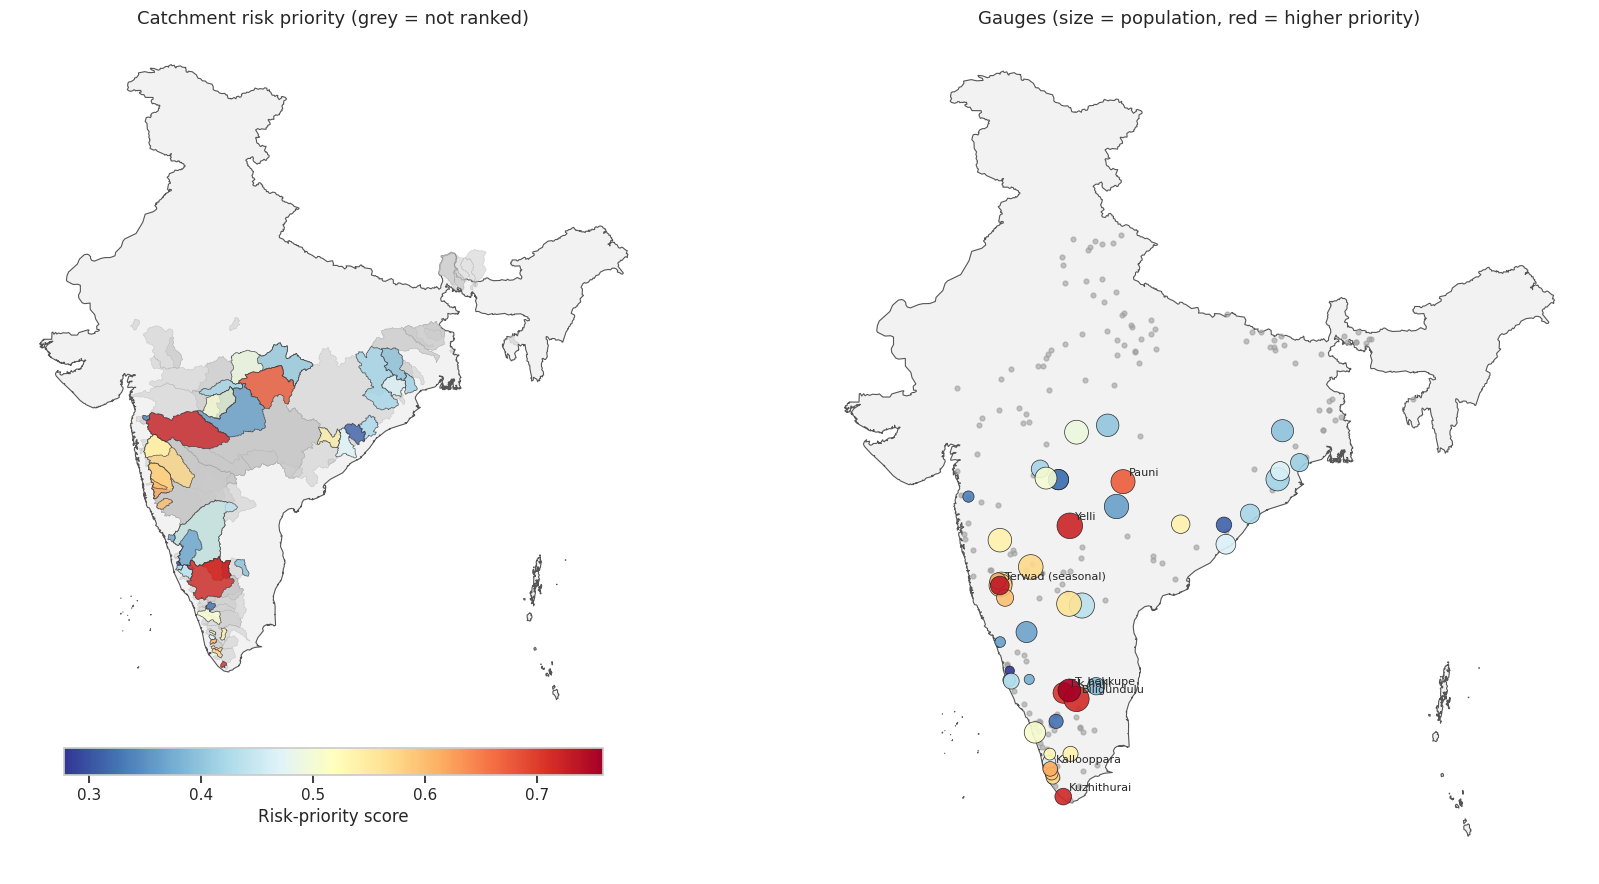

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax in axes:
    india.plot(ax=ax, color='#f2f2f2', edgecolor='#555555', linewidth=0.8)
    ax.set_axis_off()

# Left panel: catchment polygons
scored_shapes = shapes.dropna(subset=['risk_priority_score'])
shapes[shapes['risk_priority_score'].isna()].plot(ax=axes[0], color='#c9c9c9', edgecolor='#999999', linewidth=0.3, alpha=0.5)
scored_shapes.plot(ax=axes[0], column='risk_priority_score', cmap='RdYlBu_r', edgecolor='#333333', linewidth=0.5,
                   alpha=0.8, legend=True,
                   legend_kwds={'label': 'Risk-priority score', 'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.02})
axes[0].set_title('Catchment risk priority (grey = not ranked)', fontsize=13)

# Right panel: gauge points sized by population
scored_points = gauge_points.dropna(subset=['risk_priority_score']).sort_values('risk_priority_score')
gauge_points[gauge_points['risk_priority_score'].isna()].plot(ax=axes[1], color='#9e9e9e', markersize=12, alpha=0.6)
scored_points.plot(ax=axes[1], column='risk_priority_score', cmap='RdYlBu_r',
                   markersize=40 + 300 * scored_points['population_count'].rank(pct=True),
                   edgecolor='k', linewidth=0.5, alpha=0.9)
for _, row in scored_points.nlargest(8, 'risk_priority_score').iterrows():
    axes[1].annotate(row['station'], (row['longitude'], row['latitude']), xytext=(4, 4),
                     textcoords='offset points', fontsize=8)
axes[1].set_title('Gauges (size = population, red = higher priority)', fontsize=13)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'india_static_risk_map.png'), dpi=300, bbox_inches='tight')
plt.show()

### Static map of India: robustness of the priority list in the simulation

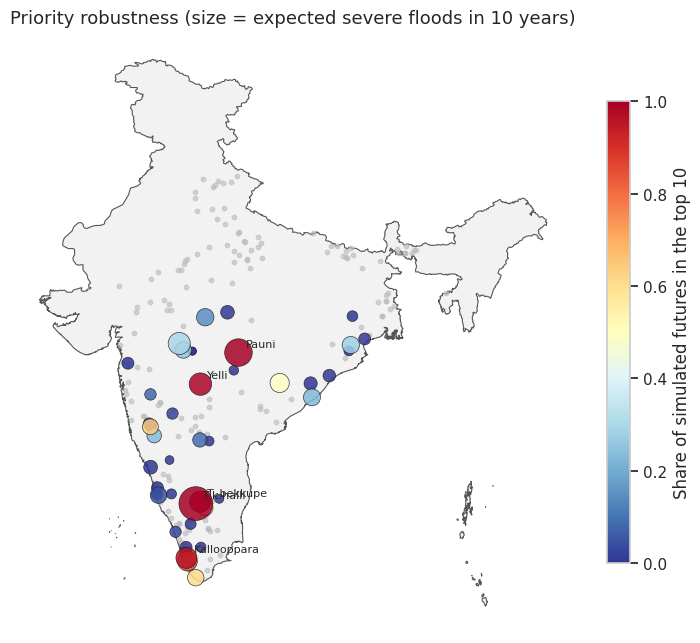

In [ ]:
sim_points = gauge_points[['gauge_id', 'geometry', 'longitude', 'latitude']].merge(
    sim[['gauge_id', 'label', 'prob_top10', 'expected_severe_floods', 'priority_status']], on='gauge_id', how='inner'
).sort_values('prob_top10')

fig, ax = plt.subplots(figsize=(9, 10))
india.plot(ax=ax, color='#f2f2f2', edgecolor='#555555', linewidth=0.8)
ax.set_axis_off()
gauge_points[~gauge_points['gauge_id'].isin(sim_points['gauge_id'])].plot(ax=ax, color='#bbbbbb', markersize=10, alpha=0.6)
sim_points.plot(ax=ax, column='prob_top10', cmap='RdYlBu_r', vmin=0, vmax=1,
                markersize=30 + 14 * sim_points['expected_severe_floods'],
                edgecolor='k', linewidth=0.5, alpha=0.85, legend=True,
                legend_kwds={'label': 'Share of simulated futures in the top 10', 'shrink': 0.6})
for _, row in sim_points[sim_points['priority_status'] == 'Robust priority'].iterrows():
    ax.annotate(row['label'].split(' (')[0], (row['longitude'], row['latitude']), xytext=(5, 4),
                textcoords='offset points', fontsize=8)
ax.set_title(f'Priority robustness (size = expected severe floods in {HORIZON_YEARS} years)', fontsize=13)
plt.savefig(os.path.join(OUTPUT_DIR, 'india_static_simulation_map.png'), dpi=300, bbox_inches='tight')
plt.show()

### Interactive catchment map

In [ ]:
import folium
import branca.colormap as cm
from folium.plugins import Fullscreen

folium_scores = risk_data[['gauge_id', 'risk_priority_score', 'hazard_score', 'exposure_score', 'priority_category']].copy()
folium_scores['priority_category'] = folium_scores['priority_category'].astype(str)   # categories cannot be written to GeoJSON

web_shapes = shapes[['gauge_id', 'geometry']].merge(folium_scores, on='gauge_id', how='left')
meta = metadata[['gaugeid', 'station', 'basin']].rename(columns={'gaugeid': 'gauge_id'})
web_shapes = web_shapes.merge(meta, on='gauge_id', how='left')

scored = web_shapes.dropna(subset=['risk_priority_score'])
unscored = web_shapes[web_shapes['risk_priority_score'].isna()]
print(f'Catchments drawn: {len(web_shapes)} | scored: {len(scored)} | not in ranking (grey): {len(unscored)}')

cmap = cm.LinearColormap(['#2c7bb6', '#ffffbf', '#d7191c'],
                         vmin=float(scored['risk_priority_score'].min()),
                         vmax=float(scored['risk_priority_score'].max()),
                         caption='Risk-priority score (blue = low, red = high)')
centroids = web_shapes.to_crs(3857).geometry.centroid.to_crs(4326)
m = folium.Map(location=[centroids.y.mean(), centroids.x.mean()], zoom_start=5, tiles='CartoDB positron')
Fullscreen().add_to(m)

if len(unscored):
    folium.GeoJson(unscored[['gauge_id', 'station', 'geometry']],
                   style_function=lambda f: {'fillColor': '#bdbdbd', 'color': '#888888', 'weight': .4, 'fillOpacity': .25},
                   tooltip=folium.GeoJsonTooltip(fields=['gauge_id', 'station'], aliases=['Gauge', 'Station']),
                   name='Not ranked').add_to(m)

folium.GeoJson(scored[['gauge_id', 'station', 'basin', 'risk_priority_score', 'hazard_score',
                       'exposure_score', 'priority_category', 'geometry']],
               style_function=lambda f: {'fillColor': cmap(f['properties']['risk_priority_score']),
                                         'color': '#444444', 'weight': .6, 'fillOpacity': .65},
               highlight_function=lambda f: {'weight': 2, 'color': 'black'},
               tooltip=folium.GeoJsonTooltip(
                   fields=['gauge_id', 'station', 'basin', 'risk_priority_score', 'hazard_score',
                           'exposure_score', 'priority_category'],
                   aliases=['Gauge', 'Station', 'Basin', 'Risk score', 'Hazard', 'Exposure', 'Category'],
                   localize=True),
               name='Risk priority').add_to(m)
cmap.add_to(m)
folium.LayerControl().add_to(m)

m.save(os.path.join(OUTPUT_DIR, 'catchment_risk_map.html'))
display(m)

Catchments drawn: 155 | scored: 46 | not in ranking (grey): 109


## 14. Export results

The exported CSV files can be used to prepare the report tables and figures.

In [ ]:
ranked.to_csv(os.path.join(OUTPUT_DIR, 'catchment_flood_risk_ranking.csv'), index=False)
hazard_data.to_csv(os.path.join(OUTPUT_DIR, 'catchment_hazard_indicators.csv'), index=False)
rank_comparison.to_csv(os.path.join(OUTPUT_DIR, 'ranking_comparison.csv'), index=False)
risk_data[['gauge_id', 'hazard_score', 'exposure_score', 'risk_priority_score',
           'priority_category', 'quadrant', 'catchment_type']].to_csv(os.path.join(OUTPUT_DIR, 'quadrants_and_typology.csv'), index=False)
sim.drop(columns=['label']).to_csv(os.path.join(OUTPUT_DIR, 'simulation_priority_stability.csv'), index=False)
print('Saved outputs to:', OUTPUT_DIR)
display(ranked[result_columns].head(10))

Saved outputs to: /content/data/outputs


,rank,gauge_id,station,basin,state,event_count,flood_frequency,severe_share,hazard_score,exposure_score,risk_priority_score,priority_category
0,1,INDOFLOODS-gauge-319,T. bekkupe,Cauvery,Karnataka,33,1.981,0.727,0.714,0.807,0.759,Very high
1,2,INDOFLOODS-gauge-643,Terwad (seasonal),Krishna,Maharashtra,69,1.693,0.420,0.710,0.764,0.737,Very high
2,3,INDOFLOODS-gauge-679,Yelli,Godavari,Maharashtra,70,1.667,1.000,0.870,0.599,0.722,Very high
3,4,INDOFLOODS-gauge-852,Kuzhithurai,West Flowing Rivers From Tadri to Kanyakumari,Tamil Nadu,37,1.891,0.405,0.768,0.674,0.719,Very high
4,5,INDOFLOODS-gauge-394,Biligundulu,Cauvery,Karnataka,419,8.596,0.079,0.696,0.733,0.714,Very high
5,6,INDOFLOODS-gauge-361,T.k.halli,Cauvery,Karnataka,219,5.220,0.767,0.884,0.565,0.707,High
6,7,INDOFLOODS-gauge-571,Pauni,Godavari,Maharashtra,242,4.346,0.595,0.913,0.500,0.676,High
7,8,INDOFLOODS-gauge-427,Kallooppara,West Flowing Rivers From Tadri to Kanyakumari,Kerala,135,3.864,0.363,0.612,0.618,0.615,High
8,9,INDOFLOODS-gauge-681,Samdoli (seasonal),Krishna,Maharashtra,26,0.469,0.577,0.572,0.643,0.607,High
9,10,INDOFLOODS-gauge-397,Gokak falls,Krishna,Karnataka,78,1.622,0.346,0.594,0.602,0.598,High
